# Final U-GFANC: Deep Learning-Based Generative Fixed-Filter Active Noise Control

**EEE 402 Final Project, Group 5.G2.**

Active noise control (ANC) cancels unwanted sound by playing "anti-noise" from a loudspeaker. The base paper,
**Unsupervised GFANC**, uses a small 1D CNN that listens to the recent noise and picks a mix of ready-made filters,
trained without labels.

We keep the paper's CNN and add four things:
1. a **Wiener filter bank** of 64 noise-type filters + 2 broadband filters;
2. **training on 230 rooms** (acoustic paths);
3. **real noise with sudden changes** (ESC-50);
4. **real-time control:** listen to the last 0.5 s, set a new filter every 0.125 s.

Every model is trained from scratch in this notebook (Kaggle, 2 × T4). The trained checkpoints are attached as the
input `updated-gfanc-ckpt`, so a run reloads them and evaluates. Remove that input to retrain everything.

# 1. Problem statement

- **The task:** noise x reaches the ear through the primary path P.
- **Our tool:** a loudspeaker plays u = W ∗ x, which reaches the ear through the secondary path S.
- **The goal:** make the leftover noise e = P∗x − S∗(W∗x) as small as possible, even when the noise changes.
- **Why not adaptive filters?** Classic adaptive filters (FxLMS) adapt slowly and can become unstable.
- **The GFANC answer:** a CNN *chooses* a ready-made filter instead, so it reacts at once and stays stable.

**The physical model.** Sound paths are linear, time-invariant systems, so each one is an impulse response, and
sounds add at the ear:

$$d[n] = (P * x)[n], \qquad u[n] = (W_t * x)[n], \qquad e[n] = d[n] - (S * u)[n],$$

where ∗ is convolution and $W_t$ is the control filter in use at time t.

## 1.1 Setup
GPU logger, libraries and all settings in one place.

In [1]:
# GPU utilisation logger (Kaggle only), started first so that it covers the whole run
import os, subprocess

ON_KAGGLE = os.path.exists("/kaggle/input")
if ON_KAGGLE:
    subprocess.Popen(
        "nvidia-smi --query-gpu=timestamp,index,utilization.gpu,memory.used "
        "--format=csv -l 20 > /kaggle/working/gpu_util.csv",
        shell=True,
    )

In [2]:
import glob, json, math, re, time, hashlib, copy, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import scipy.io as sio
import soundfile as sf
from scipy.signal import firwin, fftconvolve, lfilter, resample_poly, welch
from scipy.linalg import solve_toeplitz
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

T0 = time.time()
SMOKE = (not ON_KAGGLE) or os.environ.get("UGF_SMOKE") == "1"
LOCAL_ROOT = Path(os.environ.get("UGF_ROOT", Path.cwd().parents[1]))
OUT = (
    Path("/kaggle/working")
    if ON_KAGGLE
    else Path(os.environ.get("UGF_OUT", LOCAL_ROOT / "dev" / "smoke_out"))
)
(OUT / "runs").mkdir(parents=True, exist_ok=True)
(OUT / "results").mkdir(parents=True, exist_ok=True)
FIG = OUT / "results"

FS, TAPS = 16000, 1024  # sample rate, control-filter length (as in the paper)
WIN, HOP, FADE, LATENCY = (
    8000,
    4000,
    256,
    160,
)  # 0.5-s analysis window, 0.25-s update hop, crossfade, compute latency
LAG = 1600  # autocorrelation lags needed by the Wiener solve
CFG = dict(
    K=64,
    rho=1e-3,
    lam=1e-4,  # prototype count, white floor, Tikhonov (tuned in Section 5.1)
    K_grid=[8, 16, 32, 64],
    rho_grid=[1e-3, 1e-2, 1e-1],
    batch=256,
    steps=6000,
    lr=1e-3,
    lr_grid=[3e-4, 1e-3, 3e-3],
    lr_steps=1200,
    warmup=200,
    eval_every=500,
    log_every=100,
    ckpt_min=30,
    time_limit_h=10.5,
    p_esc=0.5,
    p_trans=0.25,
    p_event=0.3,
    n_gen=dict(train=200, val=40, test=40),
    n_val=1024,
    gfanc_max=dict(train=None, val=None, test=None),
    seeds=[0, 1, 2],
    eval_chunk=32,
    workers=4,
)
if SMOKE:
    CFG.update(
        K=8,
        K_grid=[4, 8],
        rho_grid=[1e-2],
        batch=8,
        steps=24,
        lr_grid=[1e-3],
        lr_steps=8,
        warmup=4,
        eval_every=12,
        log_every=6,
        n_gen=dict(train=6, val=3, test=3),
        n_val=16,
        seeds=[0],
        gfanc_max=dict(train=120, val=40, test=60),
        eval_chunk=8,
        workers=1,
    )
if (
    not ON_KAGGLE and os.environ.get("UGF_PILOT") == "1"
):  # local learnability pilot (short, subset; not a result)
    CFG.update(
        K=16,
        K_grid=[16],
        rho_grid=[1e-2],
        batch=64,
        steps=400,
        lr_grid=[1e-3],
        lr_steps=40,
        warmup=40,
        eval_every=100,
        log_every=100,
        n_gen=dict(train=30, val=10, test=10),
        n_val=256,
        gfanc_max=dict(train=None, val=None, test=None),
        eval_chunk=16,
        workers=4,
    )

dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_GPU = torch.cuda.device_count()
USE_AMP = dev.type == "cuda" and torch.cuda.get_device_capability()[0] >= 7  # T4 yes, GTX 1060 no
torch.backends.cudnn.benchmark = True
print(
    f"kaggle={ON_KAGGLE} smoke={SMOKE} device={dev} gpus={N_GPU} amp={USE_AMP}",
    [torch.cuda.get_device_name(i) for i in range(N_GPU)],
)
print("output ->", OUT)


def log(*a):
    print(f"[{(time.time() - T0) / 60:6.1f} min]", *a, flush=True)


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=110, bbox_inches="tight")
    plt.show()


import textwrap


def wrap(labels, n=18):
    return ["\n".join(textwrap.wrap(str(l), n)) for l in labels]


def legend_below(ax, ncol=2, fs=7):
    ax.legend(fontsize=fs, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=ncol, frameon=False)

kaggle=True smoke=False device=cuda gpus=2 amp=True ['Tesla T4', 'Tesla T4']
output -> /kaggle/working


# 2. Datasets

## 2.1 Noise datasets

| Dataset | Type | Classes | Split |
|---|---|---|---|
| GFANC synthetic (the paper's) | 1-s, 16 kHz noise in a random frequency band | 15 bands of 533 Hz (labels not used: training is unsupervised) | 80,000 / 2,000 / 2,000 |
| ESC-50 | 5-s real recordings, 44.1 kHz | 26 of 50 classes: 18 steady noises + 8 sudden events | folds 1–3 / 4 / 5 |
| DEMAND | real everyday recordings | 17 environments | test only |
| Paper's recordings | Aircraft, Drill, Motorbike | – | test only (the paper's Table 2) |

In [3]:
ESC_SUSTAINED = [
    "airplane",
    "chainsaw",
    "engine",
    "hand_saw",
    "helicopter",
    "train",
    "vacuum_cleaner",
    "washing_machine",
    "crackling_fire",
    "rain",
    "sea_waves",
    "wind",
    "thunderstorm",
    "pouring_water",
    "toilet_flush",
    "insects",
    "crickets",
    "siren",
]
ESC_EVENTS = [
    "door_wood_knock",
    "car_horn",
    "glass_breaking",
    "footsteps",
    "clapping",
    "can_opening",
    "fireworks",
    "church_bells",
]
ESC_FOLDS = dict(train=[1, 2, 3], val=[4], test=[5])


def walk_find(root, pred, max_depth=6):
    """All directories/files under root for which pred(path, files) is true (depth-limited walk)."""
    out, root = [], str(root)
    for dp, dn, fn in os.walk(root):
        if dp[len(root) :].count(os.sep) >= max_depth:
            dn[:] = []
        r = pred(dp, fn)
        if r:
            out.extend(r if isinstance(r, list) else [dp])
    return out


def fast_find(rel):
    """Look for /kaggle/input[/datasets/<owner>]/<slug>/<rel> without walking 84k files."""
    hits = []
    for base in ("/kaggle/input/datasets/*/*", "/kaggle/input/*"):
        hits += glob.glob(f"{base}/{rel}")
    return sorted(hits)


CKPT_SRC = None  # trained checkpoints of an earlier run of this notebook (evaluation-only re-run)
if ON_KAGGLE:
    IN = Path("/kaggle/input")
    _g = {
        s: fast_find(f"gfanc_synth/{n}/{n}")
        for s, n in [("train", "Training_data"), ("val", "Validate_data"), ("test", "Testing_data")]
    }
    _e, _p, _r = (
        fast_find("ESC-50-master/meta/esc50.csv"),
        fast_find("pandar_pairs.npz"),
        fast_find("gfanc_repo/models"),
    )
    _c = [
        Path(d).parents[2] for d in fast_find("runs/F_s0/done.json")
    ]  # <dataset>/runs/F_s0/done.json -> <dataset>
    CKPT_SRC = Path(_c[0]) if _c else None
if ON_KAGGLE and all(_g.values()) and _e and _p and _r:
    GF_DIRS = {s: v[0] for s, v in _g.items()}
    ESC_CSV, PANDAR, REPO = _e[0], _p[0], Path(os.path.dirname(_r[0]))
    ESC_AUDIO = os.path.join(os.path.dirname(os.path.dirname(ESC_CSV)), "audio")
elif ON_KAGGLE:  # slow fallback: walk the inputs

    def _gf(dp, fn):
        return (
            os.path.basename(dp) in ("Training_data", "Validate_data", "Testing_data")
            and sum(f.endswith(".wav") for f in fn) > 100
        )

    gdirs = walk_find(IN, _gf)
    GF_DIRS = {
        s: max([d for d in gdirs if os.path.basename(d) == n], key=lambda d: len(os.listdir(d)))
        for s, n in [("train", "Training_data"), ("val", "Validate_data"), ("test", "Testing_data")]
    }
    ESC_CSV = walk_find(IN, lambda dp, fn: [os.path.join(dp, "esc50.csv")] if "esc50.csv" in fn else None)[0]
    ESC_AUDIO = os.path.join(os.path.dirname(os.path.dirname(ESC_CSV)), "audio")
    PANDAR = walk_find(
        IN, lambda dp, fn: [os.path.join(dp, "pandar_pairs.npz")] if "pandar_pairs.npz" in fn else None
    )[0]
    repo = walk_find(
        IN,
        lambda dp, fn: [dp] if os.path.basename(dp) == "gfanc_repo" and "models" in os.listdir(dp) else None,
    )
    if not repo:  # uploaded as a zip that was not unpacked
        import zipfile

        z = walk_find(
            IN, lambda dp, fn: [os.path.join(dp, "gfanc_repo.zip")] if "gfanc_repo.zip" in fn else None
        )[0]
        zipfile.ZipFile(z).extractall("/kaggle/working/tmp_repo")
        repo = ["/kaggle/working/tmp_repo"]
    REPO = Path(repo[0])
else:  # local smoke test: the paper test set is split three ways (smoke only)
    GF_DIRS = {s: str(LOCAL_ROOT / "dev" / "data" / "Testing_data") for s in ("train", "val", "test")}
    ESC_CSV = str(LOCAL_ROOT / "dev" / "data" / "esc" / "esc50.csv")
    ESC_AUDIO = str(LOCAL_ROOT / "dev" / "data" / "esc" / "audio")
    PANDAR = str(LOCAL_ROOT / "assets" / "pandar_pairs.npz")
    REPO = LOCAL_ROOT / "assets" / "gfanc_repo"
if not ON_KAGGLE and os.environ.get("UGF_CKPT"):  # local test of the evaluation-only re-run
    CKPT_SRC = Path(os.environ["UGF_CKPT"])
print(
    json.dumps(
        dict(GF_DIRS=GF_DIRS, ESC_CSV=ESC_CSV, PANDAR=PANDAR, REPO=str(REPO), CKPT_SRC=str(CKPT_SRC)),
        indent=1,
    )
)

{
 "GF_DIRS": {
  "train": "/kaggle/input/datasets/alphabeta404/gfanc-paper-synth/gfanc_synth/Training_data/Training_data",
  "val": "/kaggle/input/datasets/alphabeta404/gfanc-paper-synth/gfanc_synth/Validate_data/Validate_data",
  "test": "/kaggle/input/datasets/alphabeta404/gfanc-paper-synth/gfanc_synth/Testing_data/Testing_data"
 },
 "ESC_CSV": "/kaggle/input/datasets/niranjankn/esc50/ESC-50-master/meta/esc50.csv",
 "PANDAR": "/kaggle/input/datasets/alphabeta404/updated-gfanc-assets/pandar_pairs.npz",
 "REPO": "/kaggle/input/datasets/alphabeta404/updated-gfanc-assets/gfanc_repo",
 "CKPT_SRC": "/kaggle/input/datasets/alphabeta404/updated-gfanc-ckpt"
}


In [4]:
# ---- GFANC synthetic set: supplied partitions (no re-splitting); duplicates audited across partitions
BAND_RE = re.compile(r"(\d+)_Frequency_from_(\d+)_to_(\d+)_Hz")


def gfanc_files(split):
    files = sorted(
        glob.glob(os.path.join(GF_DIRS[split], "*.wav")), key=lambda f: int(BAND_RE.search(f).group(1))
    )
    if not ON_KAGGLE:  # smoke: disjoint thirds of the local test folder
        n = len(files)
        files = {"train": files[: n // 2], "val": files[n // 2 : 3 * n // 4], "test": files[3 * n // 4 :]}[
            split
        ]
    m = CFG["gfanc_max"][split]
    return files[:m] if m else files


def load_gfanc(files):
    out = np.zeros((len(files), FS), np.float16)

    def rd(i):
        x, sr = sf.read(files[i], dtype="float32")
        assert sr == FS
        out[i, : min(FS, len(x))] = x[:FS]

    with ThreadPoolExecutor(16) as ex:
        list(ex.map(rd, range(len(files))))
    return out


GF, GF_META = {}, {}
for s in ("train", "val", "test"):
    f = gfanc_files(s)
    GF[s] = load_gfanc(f)
    bands = np.array([[int(BAND_RE.search(os.path.basename(p)).group(k)) for k in (2, 3)] for p in f])
    GF_META[s] = pd.DataFrame(dict(file=[os.path.basename(p) for p in f], f_lo=bands[:, 0], f_hi=bands[:, 1]))
    log(f"GFANC {s}: {GF[s].shape} from {GF_DIRS[s]}")


def fingerprint(a):
    return {hashlib.sha1(np.ascontiguousarray(r[:256]).tobytes()).hexdigest() for r in a}


fp = {s: fingerprint(GF[s]) for s in GF}
dups = {f"{a}&{b}": len(fp[a] & fp[b]) for a, b in [("train", "val"), ("train", "test"), ("val", "test")]}
print("identical GFANC clips shared between partitions:", dups)

# 15 band classes of the paper (label = which of the 15 x 533-Hz bands the noise band overlaps)
edges = np.linspace(0, FS / 2, 16)


def band_classes(lo, hi):
    return ((edges[1:] > lo) & (edges[:-1] < hi)).astype(int)


cls_counts = pd.DataFrame(
    {
        s: np.stack([band_classes(a, b) for a, b in GF_META[s][["f_lo", "f_hi"]].values]).sum(0)
        for s in GF_META
    },
    index=[f"band{k+1} {edges[k]:.0f}-{edges[k+1]:.0f} Hz" for k in range(15)],
)
display(
    Markdown(
        "**GFANC synthetic set: clips per split and how many clips cover each of the paper's 15 band classes**"
    )
)
display(cls_counts.T.assign(clips=[len(GF[s]) for s in cls_counts.columns]))

[   0.7 min] GFANC train: (80000, 16000) from /kaggle/input/datasets/alphabeta404/gfanc-paper-synth/gfanc_synth/Training_data/Training_data
[   0.7 min] GFANC val: (2000, 16000) from /kaggle/input/datasets/alphabeta404/gfanc-paper-synth/gfanc_synth/Validate_data/Validate_data
[   0.8 min] GFANC test: (2000, 16000) from /kaggle/input/datasets/alphabeta404/gfanc-paper-synth/gfanc_synth/Testing_data/Testing_data
identical GFANC clips shared between partitions: {'train&val': 0, 'train&test': 0, 'val&test': 0}


**GFANC synthetic set: clips per split and how many clips cover each of the paper's 15 band classes**

,band1 0-533 Hz,band2 533-1067 Hz,band3 1067-1600 Hz,band4 1600-2133 Hz,band5 2133-2667 Hz,band6 2667-3200 Hz,band7 3200-3733 Hz,band8 3733-4267 Hz,band9 4267-4800 Hz,band10 4800-5333 Hz,band11 5333-5867 Hz,band12 5867-6400 Hz,band13 6400-6933 Hz,band14 6933-7467 Hz,band15 7467-8000 Hz,clips
train,5145,10259,15202,19607,23607,27111,30081,32302,33853,34815,34687,33546,30988,26700,19147,80000
val,108,257,379,498,602,692,749,797,843,835,851,855,745,653,467,2000
test,130,253,366,494,580,663,712,787,800,805,806,795,742,637,513,2000


In [5]:
# ---- ESC-50: official folds; categories chosen before any test result; resampled 44.1 kHz -> 16 kHz
meta = pd.read_csv(ESC_CSV)
meta = meta[meta.category.isin(ESC_SUSTAINED + ESC_EVENTS)].copy()
meta = meta[meta.filename.apply(lambda f: os.path.exists(os.path.join(ESC_AUDIO, f)))]  # local smoke: subset
meta["kind"] = np.where(meta.category.isin(ESC_SUSTAINED), "sustained", "event")
meta["split"] = meta.fold.map({f: s for s, fs in ESC_FOLDS.items() for f in fs})
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:  # recordings never cross splits
    assert not set(meta[meta.split == a].src_file) & set(meta[meta.split == b].src_file)


def load_esc(fn):
    x, sr = sf.read(os.path.join(ESC_AUDIO, fn), dtype="float32", always_2d=True)
    x = resample_poly(x[:, 0], 160, 441).astype(np.float32) if sr == 44100 else x[:, 0]
    return np.pad(x, (0, max(0, 5 * FS - len(x))))[: 5 * FS]


with ThreadPoolExecutor(8) as ex:
    ESC_X = np.stack(list(ex.map(load_esc, meta.filename)))
meta = meta.reset_index(drop=True)
raw_example = sf.read(
    os.path.join(ESC_AUDIO, meta[meta.category == "engine"].filename.iloc[0]), dtype="float32", always_2d=True
)[0][:, 0]
log("ESC-50 selected:", ESC_X.shape)
display(Markdown("**ESC-50: clips per selected class and split**"))
display(
    meta.pivot_table(
        index=["kind", "category"], columns="split", values="filename", aggfunc="count", fill_value=0
    )
)

# frozen manifests (every crop / mixture inherits the split of its parents)
MANIFEST = {
    f"gfanc_{s}": dict(n=len(GF_META[s]), sha1=hashlib.sha1("".join(GF_META[s].file).encode()).hexdigest())
    for s in GF_META
}
MANIFEST.update(
    {
        f"esc50_{s}": dict(
            n=int((meta.split == s).sum()),
            sha1=hashlib.sha1("".join(meta[meta.split == s].filename).encode()).hexdigest(),
            files=meta[meta.split == s].filename.tolist(),
        )
        for s in ESC_FOLDS
    }
)

[   0.9 min] ESC-50 selected: (1040, 80000)


**ESC-50: clips per selected class and split**

split                      test  train  val
kind      category                         
event     can_opening         8     24    8
          car_horn            8     24    8
          church_bells        8     24    8
          clapping            8     24    8
          door_wood_knock     8     24    8
          fireworks           8     24    8
          footsteps           8     24    8
          glass_breaking      8     24    8
sustained airplane            8     24    8
          chainsaw            8     24    8
          crackling_fire      8     24    8
          crickets            8     24    8
          engine              8     24    8
          hand_saw            8     24    8
          helicopter          8     24    8
          insects             8     24    8
          pouring_water       8     24    8
          rain                8     24    8
          sea_waves           8     24    8
          siren               8     24    8
          thunderstorm        8     24    8
          toilet_flush        8     24    8
          train               8     24    8
          vacuum_cleaner      8     24    8
          washing_machine     8     24    8
          wind                8     24    8

## 2.2 Acoustic paths (rooms)

A path pair (P, S) describes one room or device:
- P: noise → ear;
- S: loudspeaker → ear.

| Group | Train / val / test | Source |
|---|---|---|
| Generated | 200 / 40 / 40 | random band-pass paths with echoes, separate seeds per split |
| Measured PANDAR | 30 / 4 / 12 | real measured headphone pairs (48 → 16 kHz) |
| Paper's measured path | test only | the authors' repository |

In [6]:
# ---- Acoustic paths. Generator A: related band-pass P/S pairs with a controlled causality margin
#      (primary-path onset minus secondary-path onset, 0-150 samples), sparse reflections and gain
def gen_pair(rng):
    ds = int(rng.integers(1, 40))
    margin = int(rng.choice([rng.integers(0, 4), rng.integers(4, 60), rng.integers(60, 151)]))

    def bp(n, delay):
        lo = rng.uniform(0.005, 0.1)
        hi = rng.uniform(max(lo + 0.1, 0.4), 0.98)
        taps = int(rng.choice([63, 127, 255]))
        h = firwin(taps, [lo, hi], pass_zero="bandpass")
        out = np.zeros(n)
        st = max(delay - taps // 2, 0)
        out[st : st + taps] = h[: n - st]
        for _ in range(int(rng.integers(0, 4))):  # causal sparse reflections
            dl = int(rng.integers(20, n // 2))
            out[dl:] += rng.uniform(-0.4, 0.4) * out[: n - dl].copy()
        return out

    P = bp(1024, ds + margin + 64) * rng.uniform(0.3, 3.0)
    S = bp(512, ds + 64)
    return P, S / np.linalg.norm(S), margin


def pad(h, n):
    h = np.asarray(h, np.float64).ravel()
    return np.pad(h, (0, n - len(h)))[:n]


PATHS = []  # dict(name, group, split, P[1024], S[512])
mat = lambda sub, f, k: sio.loadmat(REPO / "Pz and Sz" / sub / f)[k].ravel()
PATHS.append(
    dict(
        name="vent",
        group="vent (measured, paper)",
        split="test",
        P=pad(mat("RealPath", "Primary_path.mat", "Pz1"), 1024),
        S=pad(mat("RealPath", "Secondary_path.mat", "S"), 512),
    )
)
PATHS.append(
    dict(
        name="synth",
        group="synthetic (paper)",
        split="test",
        P=pad(mat("SyntheticPath", "Primary_path.mat", "Pz1"), 1024),
        S=pad(mat("SyntheticPath", "Secondary_path.mat", "S"), 512),
    )
)
pz = np.load(PANDAR)
pn, psplit = [str(s) for s in pz["names"]], [str(s) for s in pz["v3_split"]]
rng_p = np.random.default_rng(11)
tr_idx = [i for i in range(len(pn)) if psplit[i] == "train"]
val_pick = set(rng_p.choice(tr_idx, max(1, len(tr_idx) * 4 // 34), replace=False).tolist())
for i, n in enumerate(pn):
    s = "test" if psplit[i] == "test" else ("val" if i in val_pick else "train")
    PATHS.append(
        dict(name=n, group="PANDAR (measured)", split=s, P=pad(pz["P"][i], 1024), S=pad(pz["S"][i], 512))
    )
for s, seed in [("train", 1000), ("val", 2000), ("test", 3000)]:
    rng_g = np.random.default_rng(seed)
    for k in range(CFG["n_gen"][s]):
        P, S, mg = gen_pair(rng_g)
        PATHS.append(dict(name=f"gen_{s}{k:03d}", group="generated", split=s, P=P, S=S, margin=mg))

for p in PATHS:
    assert np.isfinite(p["P"]).all() and np.isfinite(p["S"]).all() and np.linalg.norm(p["S"]) > 0
PNAME = [p["name"] for p in PATHS]
P_ALL = np.stack([p["P"] for p in PATHS])
S_ALL = np.stack([p["S"] for p in PATHS])
PDF = pd.DataFrame([{k: v for k, v in p.items() if k not in ("P", "S")} for p in PATHS])
onset = lambda h: int(np.argmax(np.abs(h) > 0.1 * np.abs(h).max()))
PDF["causality_margin"] = [onset(p["P"]) - onset(p["S"]) for p in PATHS]
IDX = {s: np.where(PDF.split == s)[0] for s in ("train", "val", "test")}
TEST_GROUPS = {
    "vent": [PNAME.index("vent")],
    "synth": [PNAME.index("synth")],
    "pandar": [i for i in IDX["test"] if PDF.group[i] == "PANDAR (measured)"],
    "gen": [i for i in IDX["test"] if PDF.group[i] == "generated"],
}
display(Markdown("**Acoustic path pairs per group and split** (test paths are never used in training)"))
display(PDF.pivot_table(index="group", columns="split", values="name", aggfunc="count", fill_value=0))
MANIFEST["paths"] = PDF[["name", "group", "split"]].to_dict("list")
np.savez(OUT / "paths.npz", names=np.array(PNAME), split=PDF.split.values, P=P_ALL, S=S_ALL)
(OUT / "manifests.json").write_text(json.dumps(MANIFEST, indent=1), encoding="utf-8")

**Acoustic path pairs per group and split** (test paths are never used in training)

split,test,train,val
group,,,
PANDAR (measured),12,30,4
generated,40,200,40
synthetic (paper),1,0,0
"vent (measured, paper)",1,0,0


40596

## 2.3 Dataset visualization

- **GFANC synthetic:** the bandwidth of every clip, and the spectrum of one test clip.
- **ESC-50:** five steady real noises used in training and testing (waveform and spectrum, at 16 kHz).

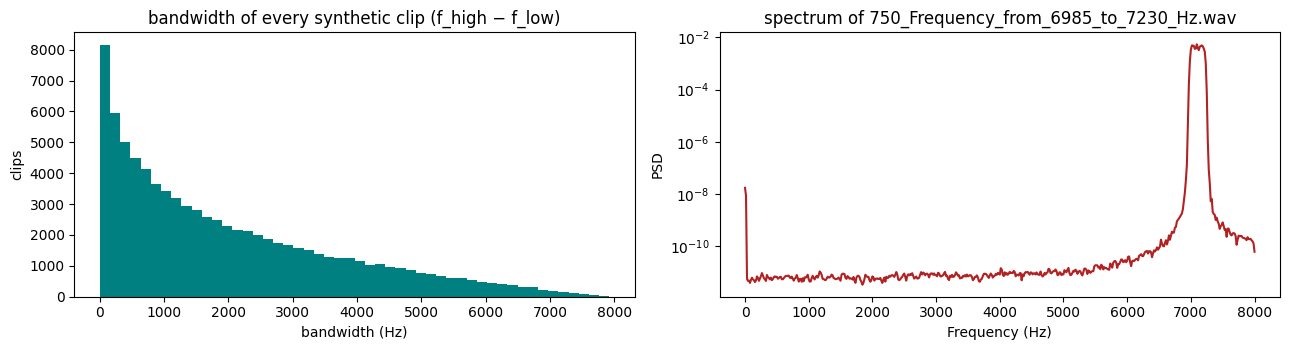

median bandwidth 1490 Hz over 84,000 clips


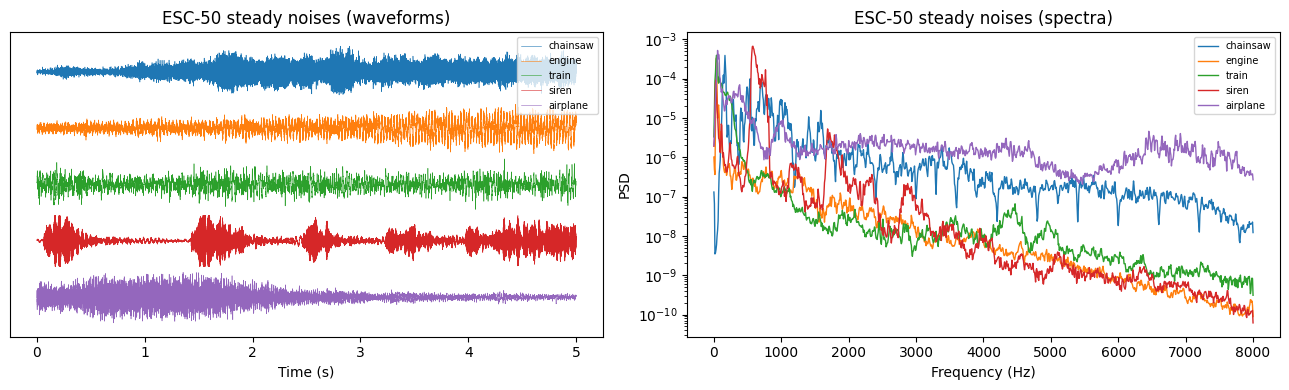

In [7]:
# GFANC synthetic: bandwidth of every clip, and the spectrum of one test clip
bw = np.concatenate([GF_META[s].f_hi.values - GF_META[s].f_lo.values for s in GF_META])
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].hist(bw, 50, color="teal")
ax[0].set_title("bandwidth of every synthetic clip (f_high − f_low)")
ax[0].set_xlabel("bandwidth (Hz)")
ax[0].set_ylabel("clips")
_names = list(GF_META["test"].file)
_k = next((i for i, n in enumerate(_names) if n.startswith("750_")), 0)
f, p = welch(GF["test"][_k].astype(np.float32), FS, nperseg=1024)
ax[1].semilogy(f, p, color="firebrick")
ax[1].set_title(f"spectrum of {_names[_k]}")
ax[1].set_xlabel("Frequency (Hz)")
ax[1].set_ylabel("PSD")
savefig("fig_data_synthetic")
print(f"median bandwidth {np.median(bw):.0f} Hz over {len(bw):,} clips")

# ESC-50: five steady noises
_cls = [c for c in ["chainsaw", "engine", "train", "siren", "airplane"] if (meta.category == c).any()]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, c in enumerate(_cls):
    x = ESC_X[meta.index[meta.category == c][0]]
    ax[0].plot(np.arange(len(x)) / FS, x / (np.abs(x).max() + 1e-9) - 2.2 * k, lw=0.4, label=c)
    f, p = welch(x, FS, nperseg=2048)
    ax[1].semilogy(f, p, lw=1, label=c)
ax[0].set_title("ESC-50 steady noises (waveforms)")
ax[0].set_xlabel("Time (s)")
ax[0].set_yticks([])
ax[0].legend(fontsize=7, loc="upper right")
ax[1].set_title("ESC-50 steady noises (spectra)")
ax[1].set_xlabel("Frequency (Hz)")
ax[1].set_ylabel("PSD")
ax[1].legend(fontsize=7)
savefig("fig_data_esc50")

# 3. Data preprocessing

1. **Resample:** ESC-50 from 44.1 kHz to 16 kHz.
2. **Keep real sound:** only 1-s crops within 30 dB of the clip's loudest second.
3. **Split first, then mix:** every crop and mixture uses one split only.
4. **Mix and add sudden changes:**
   - 50 % synthetic / 50 % ESC-50;
   - 25 % of sequences get a switch to another noise, or an event on top of it;
   - level jump −6 to +12 dB.
5. **Normalise and simulate:**
   - one volume scale per sequence, so a level jump is kept;
   - a random training room for each sequence;
   - noise at the ear d = P ∗ x.

## 3.1 Resampling and usable crops

ESC train: 624 clips, 7180 energetic sustained 1-s crops, 192 events
ESC val: 208 clips, 2399 energetic sustained 1-s crops, 64 events
ESC test: 208 clips, 2439 energetic sustained 1-s crops, 64 events


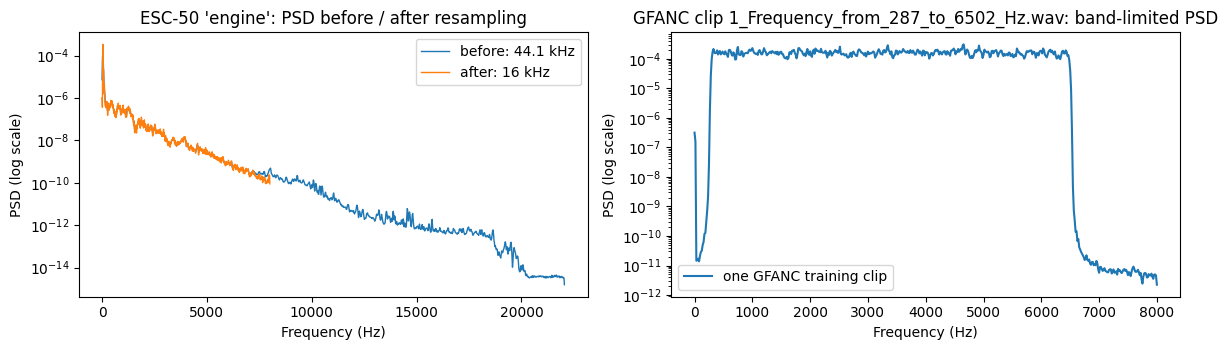

In [8]:
def crop_table(X, kinds):
    """(clip, offset) of energetic 1-s crops on a 0.25-s grid (sustained clips) and onsets (event clips)."""
    crops, onsets = [], []
    for c in range(len(X)):
        x = X[c]
        if kinds[c] == "sustained":
            offs = np.arange(0, len(x) - FS + 1, HOP)
            r = np.array([np.sqrt(np.mean(x[o : o + FS] ** 2)) for o in offs])
            ok = (r > r.max() * 10 ** (-30 / 20)) & (r > 1e-5)
            crops += [(c, int(o)) for o in offs[ok]]
        else:
            onsets.append((c, onset(x)))
    return np.array(crops, np.int64).reshape(-1, 2), np.array(onsets, np.int64).reshape(-1, 2)


ESC_SPLIT = {}
for s in ESC_FOLDS:
    m = meta[meta.split == s]
    X = ESC_X[m.index.values]
    crops, ons = crop_table(X, m.kind.values)
    ESC_SPLIT[s] = dict(X=X, crops=crops, onsets=ons, cat=m.category.values)
    print(f"ESC {s}: {len(X)} clips, {len(crops)} energetic sustained 1-s crops, {len(ons)} events")

# before / after resampling (ESC-50) and one GFANC clip
x16 = ESC_X[meta[meta.category == "engine"].index[0]]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for sig, sr, lab in [(raw_example, 44100, "before: 44.1 kHz"), (x16, FS, "after: 16 kHz")]:
    f, p = welch(sig, sr, nperseg=2048)
    ax[0].semilogy(f, p, label=lab, lw=1)
ax[0].set_title("ESC-50 'engine': PSD before / after resampling")
ax[0].set_xlabel("Frequency (Hz)")
ax[0].set_ylabel("PSD (log scale)")
ax[0].legend()
g0 = GF["train"][0].astype(np.float32)
f, p = welch(g0, FS, nperseg=1024)
ax[1].semilogy(f, p, label="one GFANC training clip")
ax[1].set_title(f"GFANC clip {GF_META['train'].file[0]}: band-limited PSD")
ax[1].set_xlabel("Frequency (Hz)")
ax[1].set_ylabel("PSD (log scale)")
ax[1].legend()
savefig("fig_pre_resampling")

## 3.2 Training sequences and room paths

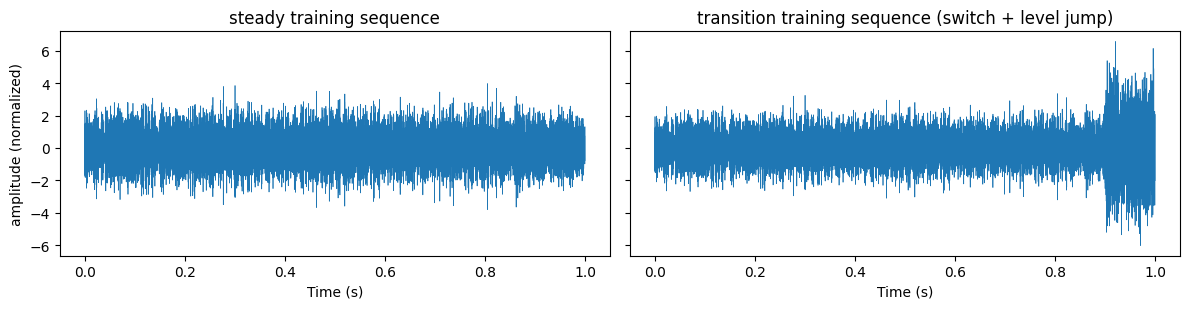

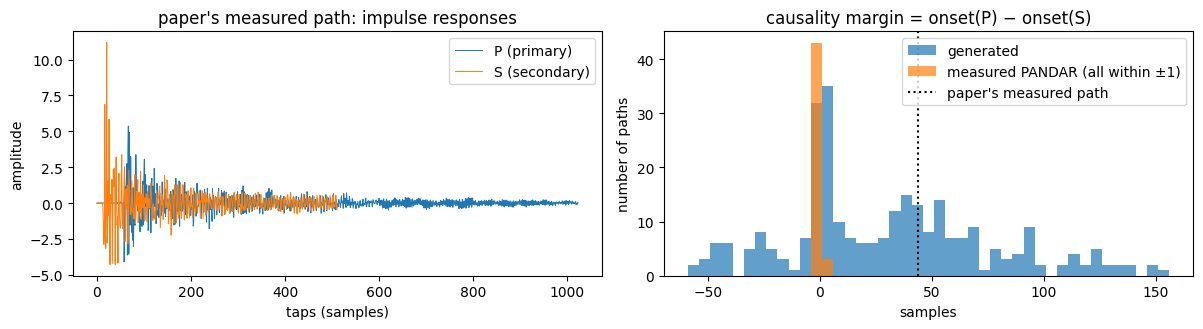

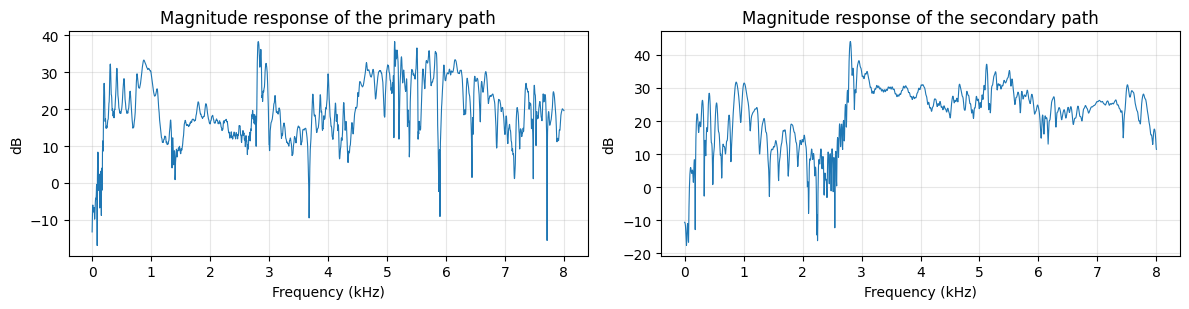

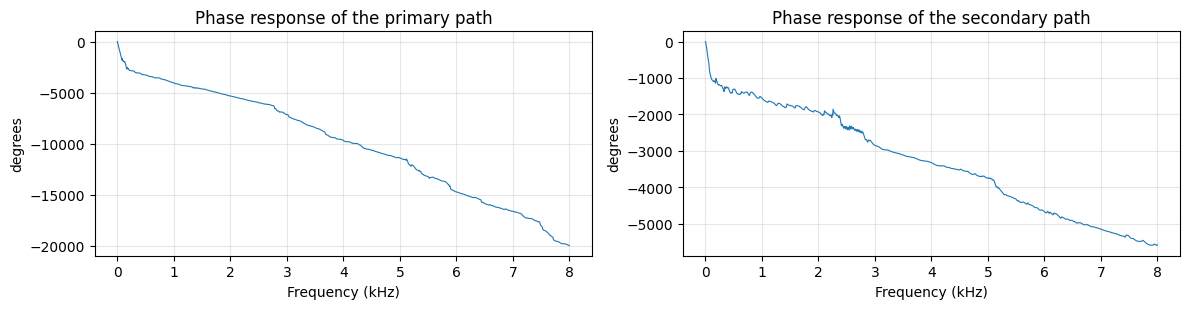

In [9]:
_GPU_DATA = {}


def gpu_data(split):
    """One GPU copy (fp16) of each split's audio, shared by all samplers."""
    if split not in _GPU_DATA:
        e = ESC_SPLIT[split]
        _GPU_DATA[split] = (
            torch.tensor(GF[split], device=dev),
            torch.tensor(e["X"], dtype=torch.float16, device=dev),
            torch.tensor(e["crops"], device=dev),
            torch.tensor(e["onsets"], device=dev),
        )
    return _GPU_DATA[split]


class Sampler:
    """Builds training / validation batches on the GPU from one split only."""

    def __init__(self, split, path_idx, p_esc, p_trans, seed):
        self.g = torch.Generator(device=dev).manual_seed(seed)
        self.gf, self.esc, self.crops, self.ons = gpu_data(
            split
        )  # fp16 [n, 16000], [m, 80000], crop / onset tables
        self.paths = torch.tensor(np.asarray(path_idx), device=dev)
        self.p_esc = p_esc if len(self.crops) else 0.0
        self.p_trans, self.t = p_trans, torch.arange(FS, device=dev)

    def r(self, *shape):
        return torch.rand(*shape, generator=self.g, device=dev)

    def ri(self, n, size):
        return torch.randint(0, n, (size,), generator=self.g, device=dev)

    def source(self, B):
        x = self.gf[self.ri(len(self.gf), B)].float()
        if self.p_esc > 0:
            c = self.crops[self.ri(len(self.crops), B)]
            xe = self.esc[c[:, :1], c[:, 1:] + self.t[None]].float()
            x = torch.where((self.r(B) < self.p_esc)[:, None], xe, x)
        return x / (x.pow(2).mean(-1, keepdim=True).sqrt() + 1e-6)

    def batch(self, B, return_meta=False):
        a = self.source(B)
        x = a
        if self.p_trans > 0:
            b = self.source(B)
            ts = (0.5 + 0.4 * self.r(B)) * FS
            ramp = torch.tensor([0, 160, 800, 1600], device=dev)[self.ri(4, B)].float()
            gain = 10 ** (torch.tensor([-6.0, -3, 0, 3, 6, 12], device=dev)[self.ri(6, B)] / 20)
            m = ((self.t[None] - ts[:, None]) / ramp.clamp(min=1)[:, None]).clamp(0, 1)
            sw = (1 - m) * a + m * gain[:, None] * b
            if len(self.ons):
                o = self.ons[self.ri(len(self.ons), B)]
                k = (o[:, 1:] + self.t[None] - ts[:, None].long()).clamp(0, self.esc.shape[1] - 1)
                ev = self.esc[o[:, :1], k].float() * (self.t[None] >= ts[:, None])
                ev = ev / (
                    ev.pow(2).sum(-1, keepdim=True) / (self.t[None] >= ts[:, None]).sum(-1, keepdim=True)
                ).sqrt().clamp(min=1e-6)
                ov = a + gain[:, None] * ev
                sw = torch.where((self.r(B) < CFG["p_event"])[:, None], ov, sw)
            x = torch.where((self.r(B) < self.p_trans)[:, None], sw, a)
        x = x / (x.pow(2).mean(-1, keepdim=True).sqrt() + 1e-6)  # one common scale per sequence
        pidx = self.paths[self.ri(len(self.paths), B)]
        return x, pidx


# two training sequences after preprocessing: a steady one and a transition
_x0, _ = Sampler("train", IDX["train"], 0.5, 0.0, 5).batch(1)
_x1, _ = Sampler("train", IDX["train"], 0.5, 1.0, 5).batch(1)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
for a, xx, t in [
    (ax[0], _x0, "steady training sequence"),
    (ax[1], _x1, "transition training sequence (switch + level jump)"),
]:
    a.plot(np.arange(FS) / FS, xx[0].cpu().numpy(), lw=0.5)
    a.set_title(t)
    a.set_xlabel("Time (s)")
ax[0].set_ylabel("amplitude (normalized)")
savefig("fig_pre_sequences")

# acoustic simulation figure (paper's measured pair)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
v = PNAME.index("vent")
ax[0].plot(P_ALL[v], lw=0.7, label="P (primary)")
ax[0].plot(S_ALL[v], lw=0.7, label="S (secondary)")
ax[0].legend()
ax[0].set_title("paper's measured path: impulse responses")
ax[0].set_xlabel("taps (samples)")
ax[0].set_ylabel("amplitude")
_bins = np.arange(PDF.causality_margin.min() - 2, PDF.causality_margin.max() + 8, 5)
ax[1].hist(PDF.causality_margin[PDF.group == "generated"], _bins, alpha=0.7, label="generated")
ax[1].hist(
    PDF.causality_margin[PDF.group == "PANDAR (measured)"],
    _bins,
    alpha=0.7,
    label="measured PANDAR (all within ±1)",
)
ax[1].axvline(
    PDF.causality_margin[PDF.name == "vent"].iloc[0], color="k", ls=":", label="paper's measured path"
)
ax[1].set_title("causality margin = onset(P) − onset(S)")
ax[1].set_xlabel("samples")
ax[1].set_ylabel("number of paths")
ax[1].legend()
savefig("fig_paths")

# the paper's Fig. 4: magnitude and phase responses of the paper's measured primary and secondary paths
fq = np.fft.rfftfreq(4096, 1 / FS) / 1000
for kind, fn in [
    ("Magnitude", lambda H: 20 * np.log10(np.abs(H) + 1e-12)),
    ("Phase", lambda H: np.degrees(np.unwrap(np.angle(H)))),
]:
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
    for a, (h, nm) in zip(ax, [(P_ALL[v], "primary"), (S_ALL[v], "secondary")]):
        a.plot(fq, fn(np.fft.rfft(h, 4096)), lw=0.8)
        a.set_title(f"{kind} response of the {nm} path")
        a.set_xlabel("Frequency (kHz)")
        a.set_ylabel("dB" if kind == "Magnitude" else "degrees")
        a.grid(alpha=0.3)
    savefig(f"fig_paper_fig4_{kind.lower()}")

## 3.3 Dataset statistics

- **GFANC synthetic:** frequency statistics of the noise bands, and the clip level, per split.
- **ESC-50:** clips, usable 1-s crops and events per split, and the clip level.
- **Acoustic paths:** the causality margin (how many samples earlier the anti-noise can arrive) per group.

In [10]:
# GFANC synthetic: band edges, bandwidth, centre frequency and level per split
rows = []
for s_ in GF_META:
    m_ = GF_META[s_]
    lvl = np.concatenate(
        [
            20 * np.log10(np.sqrt((GF[s_][i : i + 5000].astype(np.float32) ** 2).mean(1)) + 1e-12)
            for i in range(0, len(GF[s_]), 5000)
        ]
    )
    for q, v in [
        ("lower edge f_low (Hz)", m_.f_lo),
        ("upper edge f_high (Hz)", m_.f_hi),
        ("bandwidth (Hz)", m_.f_hi - m_.f_lo),
        ("centre frequency (Hz)", (m_.f_hi + m_.f_lo) / 2),
        ("clip level (dBFS)", pd.Series(lvl)),
    ]:
        rows.append(
            dict(
                split=s_,
                quantity=q,
                clips=len(m_),
                mean=v.mean(),
                std=v.std(),
                min=v.min(),
                median=v.median(),
                max=v.max(),
            )
        )
display(Markdown("**GFANC synthetic: statistics per split**"))
display(pd.DataFrame(rows).round(1))

# ESC-50: clips, usable crops and events per split
esc_rows = []
for s_ in ESC_FOLDS:
    e_ = ESC_SPLIT[s_]
    lv = 20 * np.log10(np.sqrt((e_["X"].astype(np.float64) ** 2).mean(1)) + 1e-12)
    esc_rows.append(
        dict(
            split=s_,
            clips=len(e_["X"]),
            steady_1s_crops=len(e_["crops"]),
            events=len(e_["onsets"]),
            level_mean_dB=lv.mean(),
            level_std_dB=lv.std(),
        )
    )
display(Markdown("**ESC-50: clips, usable crops and events per split**"))
display(pd.DataFrame(esc_rows).round(1))

# acoustic paths: causality margin
display(Markdown("**Acoustic paths: causality margin (samples) per group and split**"))
display(PDF.groupby(["group", "split"]).causality_margin.agg(["count", "mean", "min", "max"]).round(1))

**GFANC synthetic: statistics per split**

,split,quantity,clips,mean,std,min,median,max
0,train,lower edge f_low (Hz),80000,3994.1,2295.0,20.0,3977.0,7980.0
1,train,upper edge f_high (Hz),80000,5987.7,1751.7,56.0,6491.0,7981.0
2,train,bandwidth (Hz),80000,1993.6,1754.7,0.0,1494.0,7923.0
3,train,centre frequency (Hz),80000,4990.9,1843.4,46.0,5102.5,7980.5
4,train,clip level (dBFS),80000,-0.0,0.0,-0.0,-0.0,0.0
5,val,lower edge f_low (Hz),2000,3994.4,2297.1,28.0,3967.0,7977.0
6,val,upper edge f_high (Hz),2000,5961.4,1767.0,343.0,6438.5,7980.0
7,val,bandwidth (Hz),2000,1967.0,1769.7,2.0,1413.5,7878.0
8,val,centre frequency (Hz),2000,4977.9,1848.4,261.0,5060.0,7978.5
9,val,clip level (dBFS),2000,-0.0,0.0,-0.0,-0.0,0.0


**ESC-50: clips, usable crops and events per split**

,split,clips,steady_1s_crops,events,level_mean_dB,level_std_dB
0,train,624,7180,192,-23.0,8.9
1,val,208,2399,64,-23.0,8.5
2,test,208,2439,64,-22.6,8.3


**Acoustic paths: causality margin (samples) per group and split**

count   mean  min  max
group                  split                        
PANDAR (measured)      test      12   -0.1   -1    1
                       train     30   -0.1   -1    1
                       val        4   -0.2   -1    0
generated              test      40   29.1  -49  147
                       train    200   28.1  -56  147
                       val       40   35.2  -57  151
synthetic (paper)      test       1  128.0  128  128
vent (measured, paper) test       1   44.0   44   44

# 4. Model architecture

Three parts: a **filter bank** made for each room, the authors' **1D CNN** that weights the bank, and a
**real-time controller** that plays the mixed filter.

## 4.1 Filter bank (one per room)

- **64 noise types:** k-means on the spectra of 12,000 training clips.
- **One filter per type:** each type gets its best (Wiener) 1,024-tap filter for the room.
- **2 broadband filters:** W0 white (the paper's broadband filter) and W0 pooled.
- **The paper's bank (used in the ablation):** 15 frequency slices of W0 white.

**Wiener filter.** For a noise with autocorrelation r and a room (P, S), the best 1,024-tap filter minimises the mean
squared leftover noise. It solves the normal equations

$$R\,w = p,$$

where R is the autocorrelation matrix of the filtered reference S ∗ x and p is its cross-correlation with the
disturbance P ∗ x. Both follow directly from r, P and S. R is a Toeplitz matrix, so the system is solved quickly and
exactly (`solve_toeplitz`, Levinson recursion). A small white floor ρ is added to every noise type.

In [11]:
def autocorr_batch(x, lag):
    """Normalized (unit-power) biased autocorrelation r[0..lag] of each row of x (torch, fp32)."""
    x = x.float()
    n = x.shape[-1]
    size = 1 << (2 * n - 1).bit_length()
    X = torch.fft.rfft(x, size)
    r = torch.fft.irfft(X.real**2 + X.imag**2, size)[..., : lag + 1] / n
    return r / r[..., :1].clamp(min=1e-12)


def logpsd_feat(x):
    """Level-free log power spectrum (Welch, 512-point Hann, 50 % overlap) -> 257 bins, mean removed."""
    x = x.float()
    with torch.autocast(dev.type, enabled=False):
        X = torch.stft(
            x, 512, 256, window=torch.hann_window(512, device=x.device), center=False, return_complex=True
        )
        p = (X.real**2 + X.imag**2).mean(-1)
        lp = torch.log10(p + 1e-6 * p.mean(-1, keepdim=True) + 1e-20)
    return lp - lp.mean(-1, keepdim=True)


def wiener_bank(P, S, R, lam=CFG["lam"], rho=0.0, n=TAPS):
    """Causal least-squares controllers of length n for path (P, S) and each autocorrelation row of R."""
    P, S = np.asarray(P, np.float64), np.asarray(S, np.float64)
    need = max(len(P) - 1, n + len(S) - 2)
    a = fftconvolve(S, S[::-1])
    c = fftconvolve(P, S[::-1])
    out = np.zeros((len(R), n))
    for i, r in enumerate(np.asarray(R, np.float64)):
        r = r.copy()
        r[0] += rho * r[0]
        two = np.concatenate([r[need:0:-1], r[: need + 1]])
        off = len(S) - 1 + need
        Rr = fftconvolve(a, two)[off : off + n].copy()
        p = fftconvolve(c, two)[off : off + n]
        Rr[0] = Rr[0] * (1 + lam) + 1e-12
        out[i] = solve_toeplitz(Rr, p)
    return out


def subband_bank(c, M=15):
    """The paper's uniform DFT split of a broadband filter into M sub-filters (DC bin kept in band 1)."""
    n = len(c)
    C = np.fft.fft(c)
    step = n // (2 * M)
    subs = np.zeros((M, n))
    for m in range(1, M + 1):
        Cm = np.zeros(n, complex)
        if m != M:
            lo, hi = (m - 1) * step + 1, m * step
            Cm[lo : hi + 1] = C[lo : hi + 1]
            Cm[n - hi : n - lo + 1] = C[n - hi : n - lo + 1]
        else:
            lo, hi = (M - 1) * step + 1, n - 1 - (M - 1) * step
            Cm[lo : hi + 1] = C[lo : hi + 1]
        if m == 1:
            Cm[0] = C[0]
        subs[m - 1] = np.real(np.fft.ifft(Cm))
    return subs


from joblib import Parallel, delayed


def banks_for(idx, R, rho):
    res = Parallel(n_jobs=CFG["workers"])(delayed(wiener_bank)(P_ALL[i], S_ALL[i], R, rho=rho) for i in idx)
    return np.stack(res).astype(np.float32)


# training-noise statistics (training split only)
rng_np = np.random.default_rng(0)
n_stat = 6000 if not SMOKE else 60
gi = rng_np.choice(len(GF["train"]), min(n_stat, len(GF["train"])), replace=False)
ci = rng_np.choice(
    len(ESC_SPLIT["train"]["crops"]), min(n_stat, len(ESC_SPLIT["train"]["crops"])), replace=False
)
stat_x = np.concatenate(
    [
        GF["train"][gi].astype(np.float32),
        np.stack([ESC_SPLIT["train"]["X"][c][o : o + FS] for c, o in ESC_SPLIT["train"]["crops"][ci]]),
    ]
)
stat_src = np.r_[np.zeros(len(gi)), np.ones(len(ci))]
with torch.no_grad():
    xt = torch.tensor(stat_x, device=dev)
    R_TR = torch.cat([autocorr_batch(c, LAG) for c in xt.split(512)]).cpu().numpy()
    FEAT_TR = torch.cat([logpsd_feat(c) for c in xt.split(512)]).cpu().numpy()
R_POOL = 0.5 * R_TR[stat_src == 0].mean(0) + 0.5 * R_TR[stat_src == 1].mean(0)
R_WHITE = np.zeros(LAG + 1)
R_WHITE[0] = 1.0
log(f"noise statistics from {len(stat_x)} training crops")

from sklearn.cluster import KMeans


def prototypes(K, seed=0):
    km = KMeans(K, n_init=4, random_state=seed).fit(FEAT_TR)
    Rk = np.stack([R_TR[km.labels_ == k].mean(0) for k in range(K)])
    return km.cluster_centers_.astype(np.float32), Rk

[   1.1 min] noise statistics from 12000 training crops


## 4.2 The 1D CNN (the authors' network)

The authors' `m6_res` network, unchanged except for its output layer:
- **input:** 0.5 s of raw noise (8,000 samples);
- **output:** 66 softmax weights;
- **control filter:** W = Σ πₖ · filterₖ.

In [12]:
class ResBlock(torch.nn.Module):
    def __init__(self, prev_channel, channel, conv_kernel, conv_stride, conv_pad):
        super(ResBlock, self).__init__()
        self.res = torch.nn.Sequential(
            torch.nn.Conv1d(
                in_channels=prev_channel,
                out_channels=channel,
                kernel_size=conv_kernel,
                stride=conv_stride,
                padding=conv_pad,
            ),
            torch.nn.BatchNorm1d(channel),
            torch.nn.ReLU(),
            torch.nn.Conv1d(
                in_channels=channel,
                out_channels=channel,
                kernel_size=conv_kernel,
                stride=conv_stride,
                padding=conv_pad,
            ),
            torch.nn.BatchNorm1d(channel),
        )
        self.bn = torch.nn.BatchNorm1d(channel)
        self.relu = torch.nn.ReLU()

    def forward(self, x):
        identity = x
        x = self.res(x)
        if x.shape[1] == identity.shape[1]:
            x += identity
        elif x.shape[1] > identity.shape[1]:
            if x.shape[1] % identity.shape[1] == 0:
                x += identity.repeat(1, x.shape[1] // identity.shape[1], 1)
            else:
                raise RuntimeError("Dims in ResBlock needs to be divisible on the previous dims!!")
        else:
            if identity.shape[1] % x.shape[1] == 0:
                identity += x.repeat(1, identity.shape[1] // x.shape[1], 1)
            else:
                raise RuntimeError("Dims in ResBlock needs to be divisible on the previous dims!!")
            x = identity
        x = self.bn(x)
        x = self.relu(x)
        return x


class CNNRes(torch.nn.Module):
    def __init__(
        self, channels, conv_kernels, conv_strides, conv_padding, pool_padding, num_classes=15, head="sigmoid"
    ):
        assert len(conv_kernels) == len(channels) == len(conv_strides) == len(conv_padding)
        super(CNNRes, self).__init__()
        prev_channel = 1
        self.conv_block = torch.nn.Sequential(
            torch.nn.Conv1d(
                in_channels=prev_channel,
                out_channels=channels[0][0],
                kernel_size=conv_kernels[0],
                stride=conv_strides[0],
                padding=conv_padding[0],
            ),
            torch.nn.BatchNorm1d(channels[0][0]),
            torch.nn.ReLU(),
            torch.nn.MaxPool1d(kernel_size=4, stride=4, padding=pool_padding[0]),
        )
        prev_channel = channels[0][0]
        self.res_blocks = torch.nn.ModuleList()
        for i in range(1, len(channels)):
            block = []
            for j, conv_channel in enumerate(channels[i]):
                block.append(
                    ResBlock(prev_channel, conv_channel, conv_kernels[i], conv_strides[i], conv_padding[i])
                )
                prev_channel = conv_channel
            self.res_blocks.append(torch.nn.Sequential(*block))
        self.pool_blocks = torch.nn.ModuleList()
        for i in range(1, len(pool_padding)):
            self.pool_blocks.append(torch.nn.MaxPool1d(kernel_size=4, stride=4, padding=pool_padding[i]))
        self.global_pool = torch.nn.AdaptiveAvgPool1d(1)
        act = torch.nn.Sigmoid() if head == "sigmoid" else torch.nn.Softmax(dim=-1)  # paper: Sigmoid
        self.linear = torch.nn.Sequential(torch.nn.Linear(prev_channel, num_classes), act)

    def forward(self, inwav):
        inwav = self.conv_block(inwav)
        for i in range(len(self.res_blocks)):
            inwav = self.res_blocks[i](inwav)
            if i < len(self.pool_blocks):
                inwav = self.pool_blocks[i](inwav)
        out = self.global_pool(inwav).squeeze(-1)
        out = self.linear(out)
        return out


def m6_res(num_classes=15, head="sigmoid"):
    return CNNRes(
        channels=[[128], [128] * 2],
        conv_kernels=[80, 3],
        conv_strides=[4, 1],
        conv_padding=[38, 1],
        pool_padding=[0, 0],
        num_classes=num_classes,
        head=head,
    )


def p2p(x):  # the paper's input normalisation: frame / (max - min)
    return x / (x.amax(-1, keepdim=True) - x.amin(-1, keepdim=True)).clamp(min=1e-6)


# authors' checkpoints load into this exact class
AUTH = {}
for tag, f in [
    ("unsup", "1DCNN_SyntheticDataset_UnsupervisedLearning.pth"),
    ("sup", "1DCNN_SyntheticDataset_SupervisedLearning.pth"),
]:
    net = m6_res(15, "sigmoid")
    net.load_state_dict(torch.load(REPO / "models" / f, map_location="cpu"))
    AUTH[tag] = net.to(dev).eval()
AUTH_BANK = {
    "vent": sio.loadmat(REPO / "models" / "Pretrained_Sub_Control_filters_RealPath.mat")["Wc_v"].astype(
        np.float32
    ),
    "synth": sio.loadmat(REPO / "models" / "Pretrained_Sub_Control_filters_SyntheticPath.mat")["Wc_v"].astype(
        np.float32
    ),
}
print("authors' checkpoints loaded into the notebook's CNNRes: OK")

authors' checkpoints loaded into the notebook's CNNRes: OK


In [13]:
# layer-by-layer shapes and parameter counts for the 0.5-s window (ours) and the 1-s frame (paper)
def arch_table(net, L):
    rows, hooks = [], []

    def hook(name):
        def f(m, i, o):
            p = sum(q.numel() for q in m.parameters(recurse=False))
            mac = 0
            if isinstance(m, nn.Conv1d):
                mac = o.shape[-1] * m.out_channels * m.in_channels * m.kernel_size[0]
            elif isinstance(m, nn.Linear):
                mac = m.in_features * m.out_features
            rows.append(
                dict(layer=name, type=type(m).__name__, output_shape=tuple(o.shape[1:]), params=p, MACs=mac)
            )

        return f

    for name, m in net.named_modules():
        if len(list(m.children())) == 0:
            hooks.append(m.register_forward_hook(hook(name)))
    net.eval()
    with torch.no_grad():
        net(torch.zeros(1, 1, L, device=next(net.parameters()).device))
    for h in hooks:
        h.remove()
    return pd.DataFrame(rows)


_net = m6_res(CFG["K"] + 2, "softmax").to(dev)
AT = arch_table(_net, WIN)
display(
    Markdown(f"**Generator CNN (ours: K+2 = {CFG['K']+2} softmax outputs, 0.5-s input = 8,000 samples)**")
)
display(AT)
ARCH = dict(
    params_ours=int(sum(p.numel() for p in _net.parameters())),
    macs_ours=int(AT.MACs.sum()),
    params_paper=int(sum(p.numel() for p in m6_res(15).parameters())),
    macs_paper=int(arch_table(m6_res(15).to(dev), FS).MACs.sum()),
)
print(
    f"ours: {ARCH['params_ours']:,} parameters, {ARCH['macs_ours']/1e6:.0f} M MAC per update (every 0.25 s) | "
    f"paper: {ARCH['params_paper']:,} parameters, {ARCH['macs_paper']/1e6:.0f} M MAC per update (every 1 s)"
)
del _net

**Generator CNN (ours: K+2 = 66 softmax outputs, 0.5-s input = 8,000 samples)**

,layer,type,output_shape,params,MACs
0,conv_block.0,Conv1d,"(128, 2000)",10368,20480000
1,conv_block.1,BatchNorm1d,"(128, 2000)",256,0
2,conv_block.2,ReLU,"(128, 2000)",0,0
3,conv_block.3,MaxPool1d,"(128, 500)",0,0
4,res_blocks.0.0.res.0,Conv1d,"(128, 500)",49280,24576000
5,res_blocks.0.0.res.1,BatchNorm1d,"(128, 500)",256,0
6,res_blocks.0.0.res.2,ReLU,"(128, 500)",0,0
7,res_blocks.0.0.res.3,Conv1d,"(128, 500)",49280,24576000
8,res_blocks.0.0.res.4,BatchNorm1d,"(128, 500)",256,0
9,res_blocks.0.0.bn,BatchNorm1d,"(128, 500)",256,0


ours: 217,794 parameters, 119 M MAC per update (every 0.25 s) | paper: 211,215 parameters, 238 M MAC per update (every 1 s)


## 4.3 Parameters and architecture diagram

**Parameters** (model size 0.83 MB in float32)

,item,count
0,trainable parameters,217794
1,non-trainable parameters,0
2,"BatchNorm running statistics (stored, not trai...",1792
3,"filter bank per room (66 x 1024 taps, computed...",67584


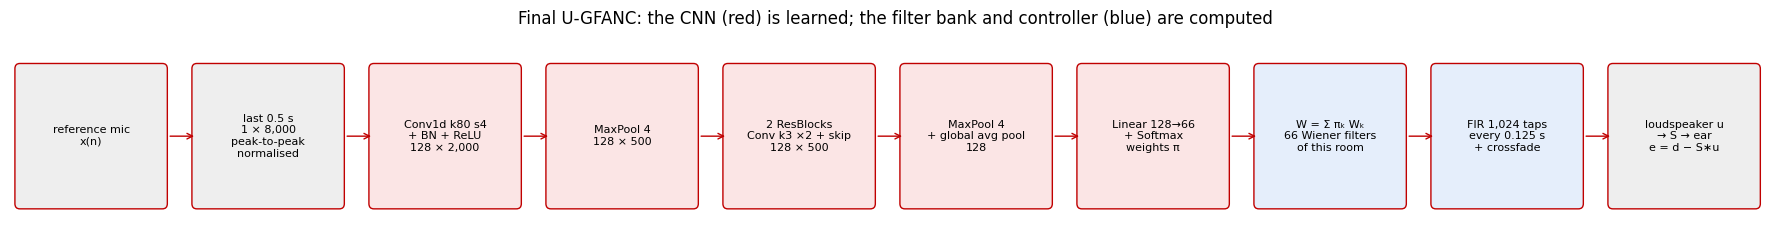

In [14]:
# trainable and non-trainable parameters
_net = m6_res(CFG["K"] + 2, "softmax")
_tr = sum(p.numel() for p in _net.parameters() if p.requires_grad)
_nt = sum(p.numel() for p in _net.parameters() if not p.requires_grad)
_bn = sum(b.numel() for n, b in _net.named_buffers() if not n.endswith("num_batches_tracked"))
PARAMS = pd.DataFrame(
    [
        dict(item="trainable parameters", count=_tr),
        dict(item="non-trainable parameters", count=_nt),
        dict(item="BatchNorm running statistics (stored, not trained)", count=_bn),
        dict(
            item=f"filter bank per room ({CFG['K'] + 2} x {TAPS} taps, computed from the room, not learned)",
            count=(CFG["K"] + 2) * TAPS,
        ),
    ]
)
display(Markdown(f"**Parameters** (model size {4 * (_tr + _nt) / 2**20:.2f} MB in float32)"))
display(PARAMS)
del _net

# architecture diagram
from matplotlib.patches import FancyBboxPatch

blocks = [
    ("reference mic\nx(n)", "#eeeeee"),
    ("last 0.5 s\n1 × 8,000\npeak-to-peak\nnormalised", "#eeeeee"),
    ("Conv1d k80 s4\n+ BN + ReLU\n128 × 2,000", "#fbe5e5"),
    ("MaxPool 4\n128 × 500", "#fbe5e5"),
    ("2 ResBlocks\nConv k3 ×2 + skip\n128 × 500", "#fbe5e5"),
    ("MaxPool 4\n+ global avg pool\n128", "#fbe5e5"),
    ("Linear 128→66\n+ Softmax\nweights π", "#fbe5e5"),
    ("W = Σ πₖ Wₖ\n66 Wiener filters\nof this room", "#e5eefb"),
    ("FIR 1,024 taps\nevery 0.125 s\n+ crossfade", "#e5eefb"),
    ("loudspeaker u\n→ S → ear\ne = d − S∗u", "#eeeeee"),
]
fig, ax = plt.subplots(figsize=(18, 2.6))
ax.set_xlim(0, len(blocks) * 1.8)
ax.set_ylim(0, 2)
ax.axis("off")
for k, (t_, c_) in enumerate(blocks):
    ax.add_patch(
        FancyBboxPatch((k * 1.8 + 0.1, 0.35), 1.45, 1.3, boxstyle="round,pad=0.05", fc=c_, ec="#C00000")
    )
    ax.text(k * 1.8 + 0.825, 1.0, t_, ha="center", va="center", fontsize=8)
    if k < len(blocks) - 1:
        ax.annotate(
            "",
            xy=(k * 1.8 + 1.9, 1.0),
            xytext=(k * 1.8 + 1.6, 1.0),
            arrowprops=dict(arrowstyle="->", color="#C00000"),
        )
ax.set_title("Final U-GFANC: the CNN (red) is learned; the filter bank and controller (blue) are computed")
savefig("fig_architecture")

## 4.4 Real-time controller

- **Listen and update:** the past 0.5 s chooses the filter for the next block.
- **Hand-over:** the new filter starts after a 10-ms compute delay and fades in over 256 samples.
- **Memory:** the filter's memory is carried across updates.
- **Start-up:** the first 0.5 s uses the broadband filter.

**Filter mixing.** With CNN outputs z, the weights are $\pi_k = e^{z_k} / \sum_j e^{z_j}$, and the control filter is
$W = \sum_k \pi_k W_k$. The weights are positive and add up to 1, so W is a weighted average of good filters.

In [15]:
def fftconv(x, h):
    """Causal linear convolution along the last axis (output length = len(x)); broadcasts over batch dims."""
    n = x.shape[-1] + h.shape[-1] - 1
    size = 1 << (n - 1).bit_length()
    return torch.fft.irfft(torch.fft.rfft(x, size) * torch.fft.rfft(h, size), size)[..., : x.shape[-1]]


def drive(x, Wb, hop=HOP, fade=FADE, latency=LATENCY):
    """Speaker signal for block-wise filters. x [B, T]; Wb [B, nb, N] (filter of block j, T = nb*hop).
    Inside block j: u = W_j * x (full history), crossfaded from W_{j-1} after `latency` samples."""
    B, T = x.shape
    N = Wb.shape[-1]
    nb = T // hop
    seg = F.pad(x, (N - 1, 0)).unfold(-1, hop + N - 1, hop)[:, :nb]
    prev = torch.cat([Wb[:, :1], Wb[:, :-1]], 1)
    yn = fftconv(seg, Wb)[..., N - 1 :]
    yo = fftconv(seg, prev)[..., N - 1 :]
    ramp = ((torch.arange(hop, device=x.device) - latency + 0.5) / fade).clamp(0, 1)
    return (ramp * yn + (1 - ramp) * yo).reshape(B, nb * hop)


def gen_filters(net, windows, bank):
    """windows [B, T, L] raw reference -> filters [B, T, N] and weights [B, T, M]."""
    B, T, L = windows.shape
    with torch.autocast(dev.type, dtype=torch.float16, enabled=USE_AMP):
        g = net(p2p(windows.reshape(B * T, 1, L)))
    g = g.float().reshape(B, T, -1)
    return torch.bmm(g, bank), g

# 5. Training and hyperparameter tuning

All choices are made on **validation** data:
- bank size K and white floor ρ, scored with no learning (nearest noise type);
- learning rate;
- filter update interval (Section 6).

## 5.1 Bank size K and white floor ρ

In [16]:
# ---- 5.1a Bank hyperparameters (K, rho) on validation, without any learning: nearest-prototype selection
VAL_SEED = 1234
val_sampler = Sampler("val", IDX["val"], CFG["p_esc"], CFG["p_trans"], VAL_SEED)
VX, VP = val_sampler.batch(CFG["n_val"])  # fixed validation recipe, reused by every run
tune_x, tune_p = Sampler("val", IDX["val"], CFG["p_esc"], 0.0, 99).batch(min(512, CFG["n_val"]))


def fixed_nmse(x, pidx, W, scored=slice(WIN, FS)):
    """NMSE (dB) of per-sequence fixed filters W [B, N] in physical order over the scored part."""
    P = torch.tensor(P_ALL, dtype=torch.float32, device=dev)[pidx]
    S = torch.tensor(S_ALL, dtype=torch.float32, device=dev)[pidx]
    d = fftconv(x, P)
    e = d - fftconv(fftconv(x, W), S)
    return 10 * torch.log10(e[:, scored].pow(2).sum(-1) / d[:, scored].pow(2).sum(-1).clamp(min=1e-12))


N_FIXED = 2  # bank members before the prototypes: W0 white (the paper's broadband filter), W0 pooled
tune_rows = []
val_paths = sorted(set(tune_p.tolist()))
_prev = (
    json.loads((CKPT_SRC / "metrics.json").read_text())
    if CKPT_SRC is not None and (CKPT_SRC / "metrics.json").exists()
    else None
)
with torch.no_grad():
    tfeat = logpsd_feat(tune_x[:, :WIN]).cpu().numpy()
    W0w = torch.tensor(banks_for(val_paths, R_WHITE[None], 0.0)[:, 0], device=dev)
    pos = torch.tensor([val_paths.index(p) for p in tune_p.tolist()], device=dev)
    base_white = fixed_nmse(tune_x, tune_p, W0w[pos]).mean().item()
    for K in (
        CFG["K_grid"] if _prev is None else []
    ):  # evaluation-only re-run: table taken from the training run
        C, Rk = prototypes(K)
        near = torch.tensor(((tfeat[:, None] - C[None]) ** 2).sum(-1).argmin(1), device=dev)
        for rho in CFG["rho_grid"]:
            bk = torch.tensor(
                banks_for(val_paths, np.r_[R_WHITE[None], R_POOL[None], Rk], rho), device=dev
            )  # [nv, K+2, N]
            w0 = fixed_nmse(tune_x, tune_p, bk[pos, 1]).mean().item()
            nb = fixed_nmse(tune_x, tune_p, bk[pos, near + N_FIXED]).mean().item()
            best = (
                torch.stack([fixed_nmse(tune_x, tune_p, bk[pos, k]) for k in range(K + N_FIXED)], 1)
                .min(1)
                .values.mean()
                .item()
            )
            tune_rows.append(
                dict(K=K, rho=rho, W0_pooled=w0, nearest_prototype=nb, best_single_member_oracle=best)
            )
            log(f"K={K} rho={rho}: nearest {nb:.2f} dB, oracle {best:.2f} dB")
TUNE_BANK = pd.DataFrame(tune_rows) if _prev is None else pd.DataFrame(_prev["tune_bank"])
bestcfg = TUNE_BANK.sort_values("nearest_prototype").iloc[0]
CFG["K"], CFG["rho"] = int(bestcfg.K), float(bestcfg.rho)
display(
    Markdown(
        f"**Bank tuning on validation** (steady validation noise × validation paths; fixed white-noise "
        f"Wiener = {base_white:.2f} dB). Chosen: K = {CFG['K']}, ρ = {CFG['rho']}"
    )
)
display(TUNE_BANK.round(2))

**Bank tuning on validation** (steady validation noise × validation paths; fixed white-noise Wiener = -16.85 dB). Chosen: K = 64, ρ = 0.001

,K,rho,W0_pooled,nearest_prototype,best_single_member_oracle
0,8,0.00,-16.96,-19.69,-21.77
1,8,0.01,-16.96,-19.48,-21.27
2,8,0.10,-17.01,-18.90,-20.29
3,16,0.00,-16.96,-20.91,-22.99
4,16,0.01,-16.96,-20.53,-22.29
5,16,0.10,-17.01,-19.51,-20.86
6,32,0.00,-16.96,-21.78,-23.77
7,32,0.01,-16.96,-21.29,-23.10
8,32,0.10,-17.01,-20.05,-21.47
9,64,0.00,-16.96,-22.89,-24.43


## 5.2 Final filter banks for every room

[   1.2 min] prototypes loaded from the training run /kaggle/input/datasets/alphabeta404/updated-gfanc-ckpt (K=64, rho=0.001)
[   1.9 min] banks: proto (328, 66, 1024), sub-band (328, 15, 1024)


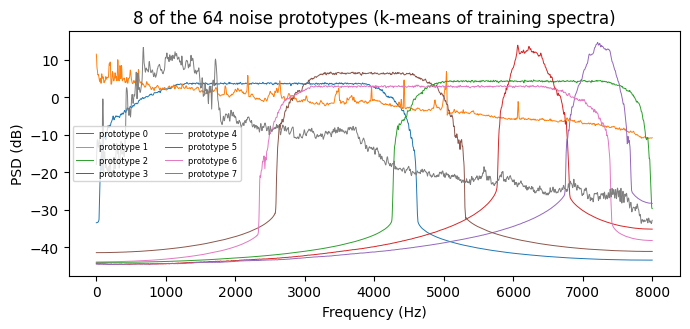

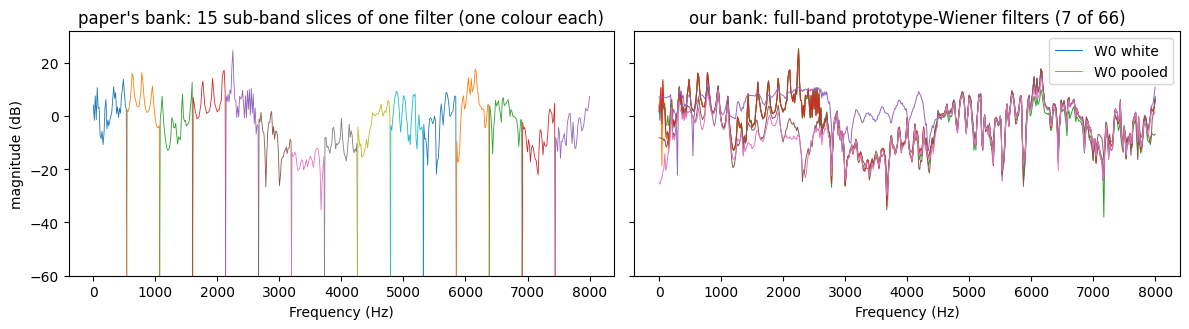

In [17]:
# ---- final banks for every path (training noise statistics only)
if (
    CKPT_SRC is not None and (CKPT_SRC / "banks.npz").exists()
):  # evaluation-only re-run: the exact prototypes the models were trained with
    _bz = np.load(CKPT_SRC / "banks.npz")
    CFG["K"], CFG["rho"] = int(_bz["K"]), float(_bz["rho"])
    PROTO_C, PROTO_R, R_POOL = _bz["proto_centroids"], _bz["proto_r"], _bz["r_pool"]
    log(f"prototypes loaded from the training run {CKPT_SRC} (K={CFG['K']}, rho={CFG['rho']})")
else:
    PROTO_C, PROTO_R = prototypes(CFG["K"])
ALL = np.arange(len(PATHS))
BANK_PROTO = banks_for(
    ALL, np.r_[R_WHITE[None], R_POOL[None], PROTO_R], CFG["rho"]
)  # [paths, K+2, N]: W0 white, W0 pooled, prototypes
W0_WHITE = banks_for(ALL, R_WHITE[None], 0.0)[:, 0]
BANK_SUB = np.stack([subband_bank(w) for w in W0_WHITE]).astype(np.float32)  # [paths, 15, N]
np.savez_compressed(
    OUT / "banks.npz",
    proto=BANK_PROTO,
    sub=BANK_SUB,
    proto_centroids=PROTO_C,
    proto_r=PROTO_R,
    r_pool=R_POOL,
    names=np.array(PNAME),
    K=CFG["K"],
    rho=CFG["rho"],
    lam=CFG["lam"],
)
T_P = torch.tensor(P_ALL, dtype=torch.float32, device=dev)
T_S = torch.tensor(S_ALL, dtype=torch.float32, device=dev)
T_BANK = {"proto": torch.tensor(BANK_PROTO, device=dev), "sub": torch.tensor(BANK_SUB, device=dev)}
log(f"banks: proto {BANK_PROTO.shape}, sub-band {BANK_SUB.shape}")
_net = m6_res(CFG["K"] + 2, "softmax").to(dev)
AT = arch_table(_net, WIN)
if int(sum(p.numel() for p in _net.parameters())) != ARCH["params_ours"]:  # only if tuning changed K
    ARCH.update(params_ours=int(sum(p.numel() for p in _net.parameters())), macs_ours=int(AT.MACs.sum()))
    display(Markdown(f"**Architecture with the tuned K = {CFG['K']}: {ARCH['params_ours']:,} parameters**"))
del _net

fr = np.fft.rfftfreq(TAPS, 1 / FS)
fr4 = np.fft.rfftfreq(4096, 1 / FS)
fig, ax = plt.subplots(figsize=(7, 3.4))
for k in range(min(8, CFG["K"])):
    rs = np.r_[PROTO_R[k][:0:-1], PROTO_R[k]] * np.hanning(2 * LAG + 1)  # symmetric autocorrelation -> PSD
    ax.plot(fr4, 10 * np.log10(np.abs(np.fft.rfft(rs, 4096)) + 1e-6), lw=0.7, label=f"prototype {k}")
ax.set_title(f"8 of the {CFG['K']} noise prototypes (k-means of training spectra)")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("PSD (dB)")
ax.legend(fontsize=6, ncol=2)
savefig("fig_prototypes")
v = PNAME.index("vent")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for m in range(15):
    ax[0].plot(fr, 20 * np.log10(np.abs(np.fft.rfft(BANK_SUB[v, m])) + 1e-6), lw=0.6)
ax[0].set_title("paper's bank: 15 sub-band slices of one filter (one colour each)")
ax[0].set_xlabel("Frequency (Hz)")
ax[0].set_ylabel("magnitude (dB)")
ax[0].set_ylim(-60, None)
for k in range(min(7, CFG["K"] + 2)):
    ax[1].plot(
        fr,
        20 * np.log10(np.abs(np.fft.rfft(BANK_PROTO[v, k])) + 1e-6),
        lw=0.7,
        label=["W0 white", "W0 pooled"][k] if k < 2 else None,
    )
ax[1].set_title("our bank: full-band prototype-Wiener filters (7 of 66)")
ax[1].set_xlabel("Frequency (Hz)")
ax[1].legend()
savefig("fig_banks")

## 5.3 Models and training loss

**Models trained from scratch** (same steps, batch and learning rate for all):

| Model | Bank / output | Noise | Rooms | Loss |
|---|---|---|---|---|
| **Final U-GFANC** (3 seeds) | 66 Wiener filters, softmax | synthetic + ESC-50 + sudden changes | 230 | real-time (causal) |
| w/o new filter bank | paper's 15 slices, sigmoid | as Final | as Final | as Final |
| w/o many rooms | as Final | as Final | paper's synthetic path | as Final |
| w/o real noise & sudden changes | as Final | synthetic only | as Final | as Final |
| w/o causal loss | as Final | as Final | as Final | paper's same-frame loss |
| U-GFANC (Wiener, modified) | paper's recipe with Wiener slices | synthetic | paper's synthetic path | paper's MSE, 1-s frames |

**Training loss** (unsupervised, no labels). For a batch of B sequences, scored on the blocks after the 0.5-s warm-up:

$$\mathcal{L} = \frac{1}{B}\sum_{b=1}^{B} 10\log_{10}\!\left(\frac{\sum_n e_b[n]^2}{\sum_n d_b[n]^2} + 10^{-4}\right).$$

The filter chosen from the past 0.5 s cancels the next 0.25 s. Gradients flow from e back through S and the filter
bank into the CNN.

## 5.4 Training code
If a model is already trained (attached checkpoint), it is loaded; otherwise it is trained from scratch.

In [18]:
# ---- 5.2 Training (all runs from scratch)
RUNS = {
    "R1_paper": dict(bank="sub", head="sigmoid", paths="synth", data="gfanc", loss="paper", win=FS),
    "F-bank": dict(bank="sub", head="sigmoid", paths="train", data="mix", loss="causal", win=WIN),
    "F-multipath": dict(bank="proto", head="softmax", paths="synth", data="mix", loss="causal", win=WIN),
    "F-esc": dict(bank="proto", head="softmax", paths="train", data="gfanc", loss="causal", win=WIN),
    "F-causal": dict(bank="proto", head="softmax", paths="train", data="mix", loss="sameframe", win=WIN),
}
for s in CFG["seeds"]:
    RUNS[f"F_s{s}"] = dict(
        bank="proto", head="softmax", paths="train", data="mix", loss="causal", win=WIN, seed=s
    )


def n_out(spec):
    return T_BANK[spec["bank"]].shape[1]


def default_filter(spec, pidx):
    b = T_BANK[spec["bank"]][pidx]
    return (
        b[:, 0] if spec["bank"] == "proto" else b.sum(1)
    )  # both = the white-noise W0 (paper's broadband filter)


def forward_loss(net, spec, x, pidx):
    """Returns (training loss, per-sequence NMSE dB over the scored part)."""
    bank = T_BANK[spec["bank"]][pidx]
    with torch.autocast(dev.type, enabled=False):
        d = fftconv(x, T_P[pidx])
        S = T_S[pidx]
    if spec["loss"] == "paper":  # paper: filter of the frame applied to the same frame, MSE
        W, _ = gen_filters(net, x[:, None, :], bank)
        with torch.autocast(dev.type, enabled=False):
            e = d - fftconv(fftconv(x, W[:, 0]), S)
            loss = e.pow(2).mean()
            nm = 10 * torch.log10(e.pow(2).sum(-1) / d.pow(2).sum(-1).clamp(min=1e-12))
        return loss, nm
    j0, nb = WIN // HOP, x.shape[-1] // HOP
    if spec["loss"] == "sameframe":  # filter from [0.5, 1) s applied to [0.5, 1) s
        W, _ = gen_filters(net, x[:, None, WIN:], bank)
        Wb = torch.cat([default_filter(spec, pidx)[:, None].expand(-1, j0, -1), W.expand(-1, nb - j0, -1)], 1)
    else:  # causal: window [t-0.5 s, t) -> block [t, t+0.25 s)
        W, _ = gen_filters(net, x.unfold(-1, WIN, HOP)[:, : nb - j0], bank)
        Wb = torch.cat([default_filter(spec, pidx)[:, None].expand(-1, j0, -1), W], 1)
    with torch.autocast(dev.type, enabled=False):
        e = d - fftconv(drive(x, Wb.float()), S)
        es, ds = e[:, j0 * HOP :].pow(2).sum(-1), d[:, j0 * HOP :].pow(2).sum(-1).clamp(min=1e-8)
        loss = (10 * torch.log10(es / ds + 1e-4)).mean()  # mean NMSE in dB (floor -40 dB), robust to outliers
        nm = 10 * torch.log10(es / ds)
    return loss, nm


def spec_sampler(spec, split, seed):
    pth = [PNAME.index("synth")] if spec["paths"] == "synth" and split == "train" else IDX[split]
    pe, pt = (CFG["p_esc"], CFG["p_trans"]) if spec["data"] == "mix" else (0.0, 0.0)
    return Sampler(split, pth, pe, pt, seed)


@torch.no_grad()
def validate(net, spec):
    net.eval()
    ls, nms = [], []  # one fixed validation set (val audio x val paths) for every run
    for x, p in zip(VX.split(128), VP.split(128)):
        l, nm = forward_loss(net, spec, x, p)
        ls.append(l * len(x))
        nms.append(nm)
    net.train()
    nm = torch.cat(nms)
    return (torch.stack(ls).sum() / len(VX)).item(), nm.mean().item()


def train_run(name, spec, steps, lr):
    rd = OUT / "runs" / name
    rd.mkdir(parents=True, exist_ok=True)
    if (rd / "done.json").exists():
        log(f"{name}: already trained, loading")
        return json.loads((rd / "done.json").read_text())
    seed = spec.get("seed", 0)
    torch.manual_seed(seed)
    net = m6_res(n_out(spec), spec["head"]).to(dev)
    model = nn.DataParallel(net) if N_GPU > 1 else net
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt,
        lambda s: min(1, (s + 1) / CFG["warmup"]) * 0.5 * (1 + math.cos(math.pi * min(s, steps) / steps))
        + 1e-3,
    )
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    sampler = spec_sampler(spec, "train", 100 + seed)
    hist, step, best, tl = [], 0, (float("inf"), None), []
    if (rd / "last.pt").exists():
        st = torch.load(rd / "last.pt", map_location=dev, weights_only=False)
        net.load_state_dict(st["net"])
        opt.load_state_dict(st["opt"])
        sched.load_state_dict(st["sched"])
        scaler.load_state_dict(st["scaler"])
        hist, step, best = st["hist"], st["step"], (st["best"], None)
        log(f"{name}: resumed at step {step}")
    t_start, t_ck, run_loss = time.time(), time.time(), torch.zeros((), device=dev)
    net.train()
    while step < steps:
        x, pidx = sampler.batch(CFG["batch"])
        loss, _ = forward_loss(model, spec, x, pidx)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(net.parameters(), 1.0)
        scaler.step(opt)
        scaler.update()
        sched.step()
        step += 1
        run_loss += loss.detach()
        if step % CFG["log_every"] == 0:
            tl.append([step, (run_loss / CFG["log_every"]).item()])
            log(
                f"{name} step {step}/{steps} loss {tl[-1][1]:.4g} lr {sched.get_last_lr()[0]:.2e}"
                f" amp-scale {scaler.get_scale():.0f} {(time.time() - t_start) / step * 1000:.0f} ms/step"
            )
            run_loss.zero_()
        if step % CFG["eval_every"] == 0 or step == steps:
            vl, vn = validate(model, spec)
            hist.append(dict(step=step, val_loss=vl, val_nmse_db=vn, lr=sched.get_last_lr()[0]))
            if vl < best[0]:
                best = (vl, step)
                torch.save(net.state_dict(), rd / "best.pt")
            log(f"{name} step {step}: val loss {vl:.4g}, val NMSE {vn:.2f} dB (best step {best[1]})")
        if time.time() - t_ck > CFG["ckpt_min"] * 60 or time.time() - T0 > CFG["time_limit_h"] * 3600:
            torch.save(
                dict(
                    net=net.state_dict(),
                    opt=opt.state_dict(),
                    sched=sched.state_dict(),
                    scaler=scaler.state_dict(),
                    hist=hist,
                    step=step,
                    best=best[0],
                ),
                rd / "last.pt",
            )
            t_ck = time.time()
            if time.time() - T0 > CFG["time_limit_h"] * 3600:
                raise SystemExit("time guard: checkpoint saved, re-run the notebook to resume")
    info = dict(
        name=name,
        spec=spec,
        steps=steps,
        lr=lr,
        hist=hist,
        train_loss=tl,
        best_val_loss=best[0],
        best_step=min(hist, key=lambda h: h["val_loss"])["step"],
        minutes=(time.time() - t_start) / 60,
    )
    (rd / "done.json").write_text(json.dumps(info, indent=1), encoding="utf-8")
    (rd / "last.pt").unlink(missing_ok=True)
    return info


def load_net(name):
    spec = RUNS.get(name) or json.loads((OUT / "runs" / name / "done.json").read_text())["spec"]
    net = m6_res(n_out(spec), spec["head"]).to(dev)
    net.load_state_dict(torch.load(OUT / "runs" / name / "best.pt", map_location=dev))
    return net.eval()

## 5.5 Learning-rate tuning

In [19]:
# ---- 5.1b learning-rate tuning (short runs of the final configuration, validation only)
import shutil

if CKPT_SRC is not None:  # evaluation-only re-run: reuse the trained checkpoints (nothing is retrained)
    for d in sorted((CKPT_SRC / "runs").iterdir()):
        if (d / "done.json").exists() and (d / "best.pt").exists():
            (OUT / "runs" / d.name).mkdir(parents=True, exist_ok=True)
            for f in ("done.json", "best.pt"):
                shutil.copy(d / f, OUT / "runs" / d.name / f)
    log("reusing trained runs:", sorted(p.name for p in (OUT / "runs").iterdir()))
LR_RUNS = {}
for lr in CFG["lr_grid"]:
    LR_RUNS[lr] = train_run(
        f"tune_lr{lr:g}", dict(RUNS[f"F_s{CFG['seeds'][0]}"], seed=0), CFG["lr_steps"], lr
    )
TUNE_LR = pd.DataFrame(
    [
        dict(
            lr=lr, best_val_nmse_db=min(h["val_nmse_db"] for h in r["hist"]), best_val_loss=r["best_val_loss"]
        )
        for lr, r in LR_RUNS.items()
    ]
)
CFG["lr"] = float(TUNE_LR.sort_values("best_val_loss").lr.iloc[0])
display(
    Markdown(
        f"**Learning-rate tuning** ({CFG['lr_steps']} steps each, validation). Chosen lr = {CFG['lr']:g}"
    )
)
display(TUNE_LR.round(4))

[   1.9 min] reusing trained runs: ['F-bank', 'F-causal', 'F-esc', 'F-multipath', 'F_s0', 'F_s1', 'F_s2', 'R1_paper', 'tune_lr0.0003', 'tune_lr0.001', 'tune_lr0.003']
[   1.9 min] tune_lr0.0003: already trained, loading
[   1.9 min] tune_lr0.001: already trained, loading
[   1.9 min] tune_lr0.003: already trained, loading


**Learning-rate tuning** (1200 steps each, validation). Chosen lr = 0.003

,lr,best_val_nmse_db,best_val_loss
0,0.0003,-19.7340,-17.3643
1,0.0010,-19.9844,-17.4642
2,0.0030,-20.3122,-17.6787


## 5.6 Training all models and their curves

[   1.9 min] ===== training R1_paper: {'bank': 'sub', 'head': 'sigmoid', 'paths': 'synth', 'data': 'gfanc', 'loss': 'paper', 'win': 16000}
[   1.9 min] R1_paper: already trained, loading
[   1.9 min] R1_paper: best val loss 0.2866 at step 5500, 30.7 min
[   1.9 min] ===== training F-bank: {'bank': 'sub', 'head': 'sigmoid', 'paths': 'train', 'data': 'mix', 'loss': 'causal', 'win': 8000}
[   1.9 min] F-bank: already trained, loading
[   1.9 min] F-bank: best val loss -15.97 at step 5500, 31.8 min
[   1.9 min] ===== training F-multipath: {'bank': 'proto', 'head': 'softmax', 'paths': 'synth', 'data': 'mix', 'loss': 'causal', 'win': 8000}
[   1.9 min] F-multipath: already trained, loading
[   1.9 min] F-multipath: best val loss -16.19 at step 4000, 31.6 min
[   1.9 min] ===== training F-esc: {'bank': 'proto', 'head': 'softmax', 'paths': 'train', 'data': 'gfanc', 'loss': 'causal', 'win': 8000}
[   1.9 min] F-esc: already trained, loading
[   1.9 min] F-esc: best val loss -16.95 at step 3000,

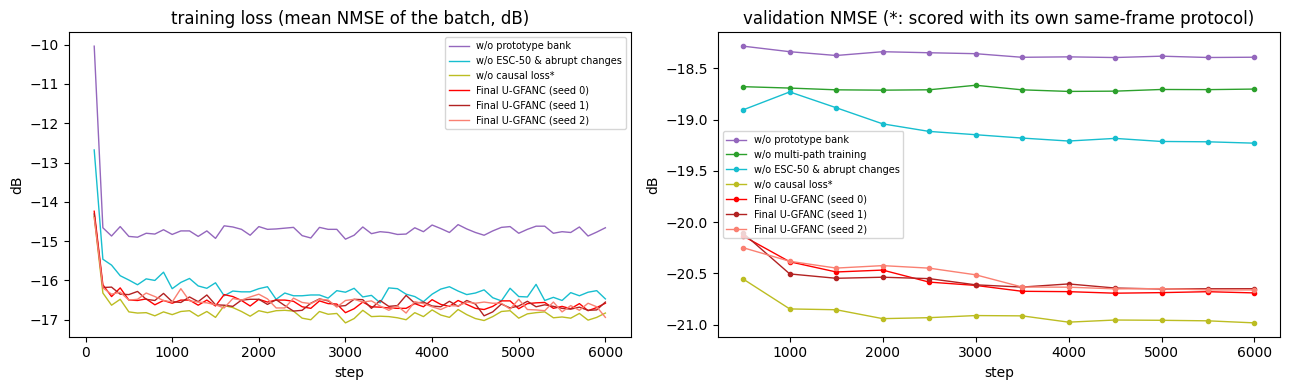

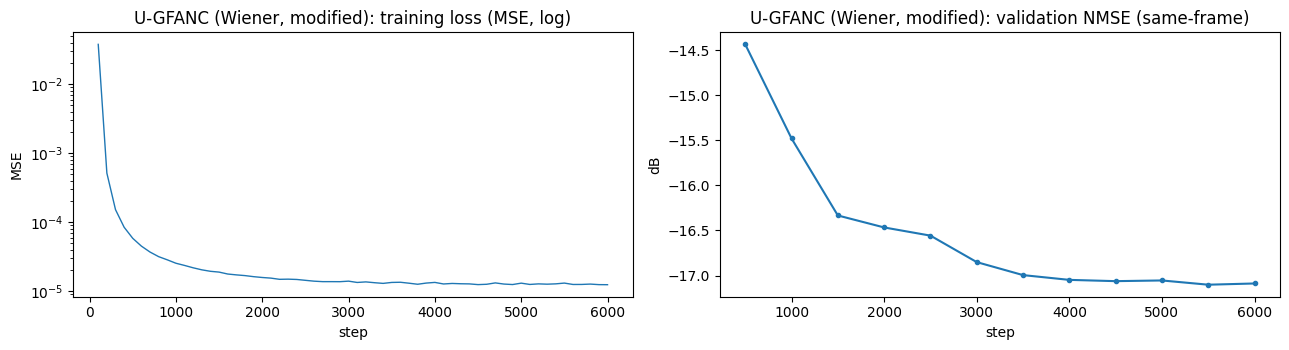

'w/o multi-path training' is left out of the training-loss panel: it trains only on the paper's (very easy) synthetic path, so its training loss sits near -38.9 dB, far below the others. Its validation curve is shown. Training loss is measured on training paths and noise, validation on held-out validation paths and noise.

In [20]:
INFO = {}
for name, spec in RUNS.items():
    log(f"===== training {name}: {spec}")
    INFO[name] = train_run(name, spec, CFG["steps"], CFG["lr"])
    log(
        f"{name}: best val loss {INFO[name]['best_val_loss']:.4g} at step {INFO[name]['best_step']}, {INFO[name]['minutes']:.1f} min"
    )
TRAIN_END = time.time()

# training loss (logged every 100 steps) and validation NMSE (every 500 steps) of every run
_tl_csv = CKPT_SRC / "train_loss_log.csv" if CKPT_SRC is not None else None
if _tl_csv is not None and _tl_csv.exists():  # evaluation-only re-run: the training run's logged losses
    TL = pd.read_csv(_tl_csv)
else:
    TL = pd.DataFrame(
        [
            dict(run=n, step=st, train_loss=l)
            for n, inf in INFO.items()
            for st, l in inf.get("train_loss", [])
        ],
        columns=["run", "step", "train_loss"],
    )
TL.to_csv(FIG / "train_loss_log.csv", index=False)
F_FAMILY = [n for n in INFO if n != "R1_paper"]
RUN_COLOR = {
    **{f"F_s{k}": c for k, c in zip(CFG["seeds"], ["red", "firebrick", "salmon"])},
    "F-bank": "C4",
    "F-multipath": "C2",
    "F-esc": "C9",
    "F-causal": "C8",
}
RUN_LABEL = {
    **{f"F_s{k}": f"Final U-GFANC (seed {k})" for k in CFG["seeds"]},
    "F-bank": "w/o prototype bank",
    "F-multipath": "w/o multi-path training",
    "F-esc": "w/o ESC-50 & abrupt changes",
    "F-causal": "w/o causal loss*",
}
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for n in F_FAMILY:
    t = TL[TL.run == n]
    if n != "F-multipath" and len(t):
        ax[0].plot(t.step, t.train_loss, lw=1, color=RUN_COLOR[n], label=RUN_LABEL.get(n, n))
    h = pd.DataFrame(INFO[n]["hist"])
    ax[1].plot(h.step, h.val_nmse_db, marker=".", lw=1, color=RUN_COLOR[n], label=RUN_LABEL.get(n, n))
ax[0].set_title("training loss (mean NMSE of the batch, dB)")
ax[0].set_xlabel("step")
ax[0].set_ylabel("dB")
ax[0].legend(fontsize=7)
ax[1].set_title("validation NMSE (*: scored with its own same-frame protocol)")
ax[1].set_xlabel("step")
ax[1].set_ylabel("dB")
ax[1].legend(fontsize=7)
savefig("fig_convergence")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
t = TL[TL.run == "R1_paper"]
if len(t):
    ax[0].semilogy(t.step, t.train_loss, lw=1)
ax[0].set_title("U-GFANC (Wiener, modified): training loss (MSE, log)")
ax[0].set_xlabel("step")
ax[0].set_ylabel("MSE")
h = pd.DataFrame(INFO["R1_paper"]["hist"])
ax[1].plot(h.step, h.val_nmse_db, marker=".")
ax[1].set_title("U-GFANC (Wiener, modified): validation NMSE (same-frame)")
ax[1].set_xlabel("step")
ax[1].set_ylabel("dB")
savefig("fig_convergence_r1")
_fm = TL[TL.run == "F-multipath"].train_loss
display(
    Markdown(
        f"'w/o multi-path training' is left out of the training-loss panel: it trains only on the paper's (very easy) synthetic "
        f"path, so its training loss sits near {(_fm.iloc[-1] if len(_fm) else float('nan')):.1f} dB, far below the others. Its validation curve is shown. "
        f"Training loss is measured on training paths and noise, validation on held-out validation paths and noise."
    )
)

# 6. Evaluation setup

- **Methods compared:**
  - FxLMS (μ = 1e-4);
  - the authors' **Supervised GFANC** and **U-GFANC (FxLMS)** checkpoints;
  - **U-GFANC (Wiener, modified)**;
  - the **fixed Wiener filter** (no CNN);
  - **Final U-GFANC** (mean of 3 seeds).
- **Test rooms:** never used in training:
  - the paper's measured path;
  - 12 new measured rooms;
  - 40 new generated rooms.
- **Performance metrics:**

| Metric | Formula | Meaning |
|---|---|---|
| NMSE | $10\log_{10}\left(\sum_n e[n]^2 / \sum_n d[n]^2\right)$ | leftover noise energy relative to the original; lower is better |
| Noise reduction | −NMSE | higher is better |
| Worst 10 % | 90th percentile of the per-stream NMSE | how good the worst cases are |
| Louder windows | share of 0.25-s windows with $\sum e^2 > \sum d^2$ | how often ANC adds noise |
| NR after a change | noise reduction in 100-ms windows around a sudden change | reaction to changes |

## 6.1 FxLMS and scoring

In [21]:
from numba import njit, prange


@njit(parallel=True, fastmath=True, cache=True)
def fx_batch(X, D, XF, Ss, mu, normalized, n):
    """Physical FxLMS for many streams: u = w.x; e = d - s*u; w += mu*e*x_f."""
    N, T = X.shape
    E = np.empty((N, T))
    Ls = Ss.shape[1]
    for i in prange(N):
        w = np.zeros(n)
        xb = np.zeros(2 * n)
        fb = np.zeros(2 * n)
        ub = np.zeros(2 * Ls)
        px, pf, pu, pw = 0, 0, 0, 0.0
        s = Ss[i]
        for k in range(T):
            px = (px - 1) % n
            xb[px] = X[i, k]
            xb[px + n] = X[i, k]
            old = fb[pf + n - 1] if k >= n else 0.0
            pf = (pf - 1) % n
            fb[pf] = XF[i, k]
            fb[pf + n] = XF[i, k]
            pw += XF[i, k] * XF[i, k] - old * old
            y = 0.0
            for j in range(n):
                y += w[j] * xb[px + j]
            pu = (pu - 1) % Ls
            ub[pu] = y
            ub[pu + Ls] = y
            a = 0.0
            for j in range(Ls):
                a += s[j] * ub[pu + j]
            e = D[i, k] - a
            E[i, k] = e
            g = mu * e / (pw + 1e-6) if normalized else mu * e
            for j in range(n):
                w[j] += g * fb[pf + j]
            if not np.isfinite(e):
                for kk in range(k, T):
                    E[i, kk] = np.inf
                break
    return E


def fx_run(X, pidx, mu, normalized=False):
    X = np.asarray(X, np.float64)
    P, S = P_ALL[pidx], S_ALL[pidx]
    D = np.stack([lfilter(P[i], 1, X[i]) for i in range(len(X))])
    XF = np.stack([lfilter(S[i], 1, X[i]) for i in range(len(X))])
    return fx_batch(X, D, XF, S.astype(np.float64), mu, normalized, TAPS), D


class Method:
    """A GFANC-style controller: one FIR per block, generated from the past window (or fixed)."""

    def __init__(self, kind, win=WIN, hop=HOP, net=None, bank="proto", first="default"):
        self.kind, self.win, self.hop, self.net, self.bank, self.first = kind, win, hop, net, bank, first

    def bank_of(self, pidx):
        if self.bank == "auth":  # authors' pre-trained banks on their two paths, transfer protocol elsewhere
            b = T_BANK["sub"][pidx].clone()
            for nm in ("vent", "synth"):
                m = pidx == PNAME.index(nm)
                if m.any():
                    b[m] = torch.tensor(AUTH_BANK[nm], device=dev)
            return b
        return T_BANK[self.bank][pidx]

    @torch.no_grad()
    def filters(self, x, pidx):
        """Block filters [B, nb, N] for stream batch x [B, T] (blocks of self.hop)."""
        B, T = x.shape
        nb = T // self.hop
        j0 = self.win // self.hop
        if self.kind == "fixed":
            return torch.tensor(W0_WHITE, device=dev)[pidx][:, None].expand(B, nb, TAPS)
        bank = self.bank_of(pidx)
        wins = x.unfold(-1, self.win, self.hop)[:, : nb - j0]  # [B, nb-j0, win]: past audio only
        if self.kind == "cnn":
            W = gen_filters(self.net, wins, bank)[0]
        else:  # nearest prototype (no learning)
            f = logpsd_feat(wins.reshape(-1, self.win)).cpu().numpy()
            k = torch.tensor(((f[:, None] - PROTO_C[None]) ** 2).sum(-1).argmin(1), device=dev).reshape(B, -1)
            W = torch.gather(bank, 1, (k + N_FIXED)[..., None].expand(-1, -1, TAPS))
        first = (
            torch.zeros(B, TAPS, device=dev)
            if self.first == "zero"
            else (bank[:, 0] if self.bank == "proto" else bank.sum(1))
        )
        return torch.cat([first[:, None].expand(-1, j0, -1), W], 1)

    @torch.no_grad()
    def run(self, X, pidx, plant=None):
        """X [N, T]; pidx = calibrated path (its bank); plant = true path (default: pidx). Returns e, d (numpy)."""
        plant = pidx if plant is None else plant
        es, ds = [], []
        for s in range(0, len(X), CFG["eval_chunk"]):
            x = torch.tensor(X[s : s + CFG["eval_chunk"]], dtype=torch.float32, device=dev)
            p = torch.tensor(pidx[s : s + CFG["eval_chunk"]], device=dev)
            q = torch.tensor(plant[s : s + CFG["eval_chunk"]], device=dev)
            x = x[:, : x.shape[-1] // self.hop * self.hop]
            u = drive(x, self.filters(x, p), hop=self.hop)
            d = fftconv(x, T_P[q])
            e = d - fftconv(u, T_S[q])
            es.append(e.cpu().numpy())
            ds.append(d.cpu().numpy())
        return np.concatenate(es), np.concatenate(ds)

    @torch.no_grad()
    def per_file(self, X, pidx):
        """The paper's protocol: the filter predicted from each 1-s file is applied to that same file."""
        out = []
        for s in range(0, len(X), 256):
            x = torch.tensor(X[s : s + 256], dtype=torch.float32, device=dev)
            p = torch.tensor(pidx[s : s + 256], device=dev)
            if self.kind == "cnn":
                W = gen_filters(self.net, x[:, None], self.bank_of(p))[0][:, 0]
            elif self.kind == "nearest":
                k = torch.tensor(
                    ((logpsd_feat(x).cpu().numpy()[:, None] - PROTO_C[None]) ** 2).sum(-1).argmin(1),
                    device=dev,
                )
                W = self.bank_of(p)[torch.arange(len(x)), k + N_FIXED]
            else:
                W = torch.tensor(W0_WHITE, device=dev)[p]
            d = fftconv(x, T_P[p])
            e = d - fftconv(fftconv(x, W), T_S[p])
            out.append(nmse_db(e.cpu().numpy(), d.cpu().numpy(), 0))
        return np.concatenate(out)


def nmse_db(e, d, a=FS, b=None):
    """NMSE in dB over samples [a, b); capped at +20 dB (a diverged controller counts as +20 dB)."""
    with np.errstate(over="ignore", invalid="ignore"):
        v = 10 * np.log10(
            np.sum(np.asarray(e[..., a:b], np.float64) ** 2, -1)
            / np.maximum(np.sum(np.asarray(d[..., a:b], np.float64) ** 2, -1), 1e-20)
        )
    return np.where(np.isfinite(v), np.minimum(v, 20.0), 20.0)


def dash(df, nd=2):
    """Display helper: '–' = not applicable / not reported by the paper."""
    return df.round(nd).astype(object).where(df.notna(), "–")

## 6.2 Test data

In [22]:
# ---- evaluation data (fixed seeds; the same streams for every method)
def no_silence(x, block=HOP, rel_db=-40.0):
    """True if no 0.25-s block is (near-)silent (short ESC-50 clips are zero-padded; NMSE is undefined on silence)."""
    b = x[: len(x) // block * block].reshape(-1, block)
    r = np.sqrt(np.mean(b.astype(np.float64) ** 2, -1))
    return bool(r.min() > np.sqrt(np.mean(x.astype(np.float64) ** 2)) * 10 ** (rel_db / 20))


def rmsn(X):
    X = np.asarray(X, np.float32)
    return X / np.sqrt(np.mean(X**2, -1, keepdims=True) + 1e-12)


def esc_steady(split):
    e = ESC_SPLIT[split]
    m = meta[meta.split == split].reset_index(drop=True)
    return rmsn([e["X"][i] for i in range(len(m)) if m.kind[i] == "sustained" and no_silence(e["X"][i])])


TR_META = {}


def make_transitions(split, seed, levels=(-6, 0, 3, 6, 12)):
    """10-s streams with a change at 5 s: class switch (10-ms ramp) or event onset over a continuing background."""
    rng = np.random.default_rng(seed)
    em = meta[meta.split == split].reset_index(drop=True)
    ev_idx = np.where(em.kind == "event")[0]
    su_idx = np.array(
        [i for i in np.where(em.kind == "sustained")[0] if no_silence(ESC_SPLIT[split]["X"][i])]
    )
    X, info = [], []
    for k in range(len(su_idx) if not SMOKE else min(4, len(su_idx))):
        a, b = su_idx[k], rng.choice([i for i in su_idx if em.category[i] != em.category[su_idx[k]]])
        xa, xb = ESC_SPLIT[split]["X"][a], ESC_SPLIT[split]["X"][b]
        jump = float(rng.choice(levels))
        g = 10 ** (jump / 20)
        xa = xa / np.sqrt(np.mean(xa**2) + 1e-12)
        xb = xb / np.sqrt(np.mean(xb**2) + 1e-12) * g
        if rng.random() < 0.3 and len(ev_idx):
            ev = ESC_SPLIT[split]["X"][rng.choice(ev_idx)]
            ev = ev[onset(ev) :]
            ev = ev / np.sqrt(np.mean(ev[:FS] ** 2) + 1e-12) * g
            x = np.r_[xa, xa[::-1]].copy()
            x[5 * FS : 5 * FS + len(ev)] += ev[: 5 * FS]
            kind = "event onset"
        else:
            r = np.clip((np.arange(10 * FS) - 5 * FS) / 160, 0, 1)
            x = (1 - r) * np.r_[xa, xa] + r * np.r_[xb, xb]
            kind = "noise switch"
        X.append(x)
        info.append(dict(kind=kind, jump_db=jump))
    TR_META[split] = pd.DataFrame(info)
    return rmsn(X)


def gfanc_streams(split):
    g = GF[split].astype(np.float32)
    n = len(g) // 10 * 10
    return rmsn(g[:n].reshape(-1, 10 * FS))


def assign_paths(n, group_idx, seed=0):
    return np.asarray(group_idx)[np.random.default_rng(seed).permutation(n) % len(group_idx)]


# DEMAND (external test): channel 1 of every 16-kHz environment, 6 x 10 s from [60, 300) s
if ON_KAGGLE:
    DM_FILES = sorted({os.path.realpath(f) for f in fast_find("*_16k/*/ch01.wav")})
    dm_env = lambda f: Path(f).parent.name
else:
    DM_FILES = sorted(
        glob.glob(
            os.environ.get("UGF_DEMAND", str(LOCAL_ROOT.parent / "research" / "data" / "raw" / "demand"))
            + "/*.wav"
        )
    )
    dm_env = lambda f: Path(f).stem
if SMOKE:
    DM_FILES = DM_FILES[:3]
DX, DENV = [], []
for f in DM_FILES:
    x, sr = sf.read(f, dtype="float32", always_2d=True)
    x = x[:, 0]
    for k in range(6):
        DX.append(x[(60 + 40 * k) * FS : (70 + 40 * k) * FS])
        DENV.append(dm_env(f))
DX = rmsn(DX)
DENV = np.array(DENV)
print(f"DEMAND: {len(set(DENV))} environments, {len(DX)} streams of 10 s")

G_PAPER, G_MEAS, G_GEN = "paper's measured path", "new measured paths (12)", "new generated paths (40)"
GROUPS = {G_PAPER: TEST_GROUPS["vent"], G_MEAS: TEST_GROUPS["pandar"], G_GEN: TEST_GROUPS["gen"]}
VGROUPS = {"val": list(IDX["val"])}  # validation uses the validation paths
DATA = {
    "test": {
        "GFANC synthetic: switching every 1 s": gfanc_streams("test"),
        "ESC-50 steady": esc_steady("test"),
        "ESC-50 abrupt changes": make_transitions("test", 2024),
        "DEMAND (unseen dataset)": DX,
    },
    "val": {
        "GFANC synthetic: switching every 1 s": gfanc_streams("val"),
        "ESC-50 steady": esc_steady("val"),
        "ESC-50 abrupt changes": make_transitions("val", 77),
    },
}
PERFILE = {"test": rmsn(GF["test"]), "val": rmsn(GF["val"])}
for sp, dd in DATA.items():
    print(sp, {k: v.shape for k, v in dd.items()})

DEMAND: 17 environments, 102 streams of 10 s
test {'GFANC synthetic: switching every 1 s': (200, 160000), 'ESC-50 steady': (138, 80000), 'ESC-50 abrupt changes': (138, 160000), 'DEMAND (unseen dataset)': (102, 160000)}
val {'GFANC synthetic: switching every 1 s': (200, 160000), 'ESC-50 steady': (130, 80000), 'ESC-50 abrupt changes': (130, 160000)}


## 6.3 Methods and filter update interval

In [23]:
# ---- methods; the update hop of our models is chosen on validation (Section 5.1)
AUTH_M = {
    "Supervised GFANC (FxLMS)": Method("cnn", FS, FS, AUTH["sup"], "auth", "zero"),
    "U-GFANC (FxLMS)": Method("cnn", FS, FS, AUTH["unsup"], "auth", "zero"),
}
hop_rows = []
for hop in [2000, 4000, 8000] if not SMOKE else [4000]:
    m = Method("cnn", WIN, hop, load_net(f"F_s{CFG['seeds'][0]}"))
    v = [
        float(nmse_db(*m.run(X, assign_paths(len(X), VGROUPS["val"], 7))).mean())
        for X in DATA["val"].values()
    ]
    hop_rows.append(dict(hop_s=hop / FS, val_nmse_db=float(np.mean(v))))
TUNE_HOP = pd.DataFrame(hop_rows)
HOP_EVAL = int(round(TUNE_HOP.sort_values("val_nmse_db").hop_s.iloc[0] * FS))
display(Markdown(f"**Update hop of our models on validation** (trained with 0.25 s) → {HOP_EVAL / FS:g} s"))
display(TUNE_HOP.round(2))

SEEDS = [f"F_s{s}" for s in CFG["seeds"]]
M = dict(AUTH_M)
M["U-GFANC (Wiener, modified)"] = Method("cnn", FS, FS, load_net("R1_paper"), "sub")
M["Fixed Wiener filter (no CNN)"] = Method("fixed", bank="sub")
for s in SEEDS:
    M[s] = Method("cnn", WIN, HOP_EVAL, load_net(s))
ABL_NAMES = {
    "F-bank": "Final w/o prototype bank (paper's 15 sub-bands)",
    "F-multipath": "Final w/o multi-path training (paper's path only)",
    "F-esc": "Final w/o ESC-50 & abrupt changes (synthetic noise only)",
    "F-causal": "Final w/o causal loss (paper's same-frame loss)",
}
for r, lab in ABL_NAMES.items():
    M[lab] = Method("cnn", WIN, HOP_EVAL, load_net(r), RUNS[r]["bank"])
OURS = "Final U-GFANC (ours)"
MAIN = [
    "Supervised GFANC (FxLMS)",
    "U-GFANC (FxLMS)",
    "U-GFANC (Wiener, modified)",
    "Fixed Wiener filter (no CNN)",
    OURS,
]
ABL = [OURS] + list(ABL_NAMES.values()) + ["U-GFANC (Wiener, modified)", "Fixed Wiener filter (no CNN)"]
MCOL = {
    "Supervised GFANC (FxLMS)": "C0",
    "U-GFANC (FxLMS)": "C1",
    "Fixed Wiener filter (no CNN)": "gray",
    OURS: "red",
    ABL_NAMES["F-bank"]: "C4",
    ABL_NAMES["F-multipath"]: "C2",
    ABL_NAMES["F-esc"]: "C9",
    ABL_NAMES["F-causal"]: "C8",
    "U-GFANC (Wiener, modified)": "C5",
}

**Update hop of our models on validation** (trained with 0.25 s) → 0.125 s

,hop_s,val_nmse_db
0,0.12,-21.36
1,0.25,-21.00
2,0.50,-20.50


## 6.4 Running every method on every test set

In [24]:
# ---- run every method on every dataset x path group (validation first, then test)
RES, PSTREAM, CURVE, PIDX, NRW = [], {}, {}, {}, {}
W100 = 1600  # 100-ms windows, from 1 s before to 3 s after the change


def nr_windows(e, d, t0=4 * FS, t1=8 * FS):
    e = np.asarray(e[:, t0:t1], np.float64).reshape(len(e), -1, W100)
    d = np.asarray(d[:, t0:t1], np.float64).reshape(len(d), -1, W100)
    return 10 * np.log10(np.sum(d**2, -1) / np.maximum(np.sum(e**2, -1), 1e-30))


for split in ("test",):
    groups = GROUPS
    for gname, gidx in groups.items():
        pidx = assign_paths(len(PERFILE[split]), gidx, 4)
        for mname, m in M.items():  # GFANC synthetic, per file (paper protocol)
            nm = m.per_file(PERFILE[split], pidx)
            PSTREAM[(split, "GFANC synthetic: per file", gname, mname)] = nm
            RES.append(
                dict(
                    split=split,
                    dataset="GFANC synthetic: per file",
                    group=gname,
                    method=mname,
                    nmse=float(nm.mean()),
                    worst10=float(np.percentile(nm, 90)),
                )
            )
        for dname, X in DATA[split].items():
            pidx = assign_paths(len(X), gidx, 11 + list(DATA[split]).index(dname))
            PIDX[(split, dname, gname)] = pidx
            for mname, m in M.items():
                e, d = m.run(X, pidx)
                nm = nmse_db(e, d)
                PSTREAM[(split, dname, gname, mname)] = nm
                w, wd = e[:, FS:].reshape(len(e), -1, HOP).astype(np.float64), d[:, FS:].reshape(
                    len(d), -1, HOP
                ).astype(np.float64)
                rec = dict(
                    split=split,
                    dataset=dname,
                    group=gname,
                    method=mname,
                    nmse=float(nm.mean()),
                    worst10=float(np.percentile(nm, 90)),
                    amplifying_pct=float(100 * np.mean(np.sum(w**2, -1) > np.sum(wd**2, -1))),
                )
                if dname == "ESC-50 abrupt changes" and split == "test":
                    NRW[(gname, mname)] = nr_windows(e, d)
                if dname == "ESC-50 abrupt changes":
                    rec["nr_0_100ms"] = float(-nmse_db(e, d, 5 * FS, 5 * FS + 1600).mean())
                    rec["nr_100_500ms"] = float(-nmse_db(e, d, 5 * FS + 1600, 5 * FS + 8000).mean())
                    if split == "test" and gname == G_PAPER:
                        CURVE[mname] = (e[0], d[0])
                RES.append(rec)
        log(f"{split} / {gname} done")
RES = pd.DataFrame(RES)

# seeds -> one "Final U-GFANC (ours)" row (mean of the three seeds; per-stream values averaged for paired tests)
_seed = RES[RES.method.isin(SEEDS)]
_agg = (
    _seed.groupby(["split", "dataset", "group"], as_index=False).mean(numeric_only=True).assign(method=OURS)
)
SEED_SD = _seed.groupby(["split", "dataset", "group"]).nmse.std()
RES = pd.concat([RES[~RES.method.isin(SEEDS)], _agg], ignore_index=True)
for g in GROUPS:
    NRW[(g, OURS)] = np.mean([NRW[(g, s_)] for s_ in SEEDS], 0)
for k in {k[:3] for k in PSTREAM if k[3] in SEEDS}:
    PSTREAM[k + (OURS,)] = np.mean([PSTREAM[k + (s,)] for s in SEEDS], 0)
RES.to_csv(FIG / "results_all.csv", index=False)
log("evaluation done")

[   3.1 min] test / paper's measured path done
[   3.9 min] test / new measured paths (12) done
[   4.8 min] test / new generated paths (40) done
[   4.8 min] evaluation done


# 7. Results: comparison with existing work

## 7.1 The paper's Table 2
The paper's three recordings, on the paper's measured path, scored over the whole 10-s clip.

In [25]:
# ---- the paper's Table 2 clips (paper's measured path, paper level: raw wav resampled to 16 kHz), NMSE over the whole clip
def load16(path):
    x, sr = sf.read(str(path), dtype="float64", always_2d=True)
    x = x[:, 0]
    g = math.gcd(FS, sr)
    return resample_poly(x, FS // g, sr // g) if sr != FS else x


CLIPS = {
    n: load16(REPO / "Noise Examples" / "Real_noises" / f"{f}.wav")
    for n, f in [("Aircraft", "Aircraft"), ("Drill", "Handheld drill"), ("Motorbike", "Motorbike")]
}
PAPER_T2 = {
    "FxLMS (μ = 1e-4)": (-3.54, -4.32),
    "Supervised GFANC (FxLMS)": (-11.68, -7.97),
    "U-GFANC (FxLMS)": (-12.65, -9.04),
}
T2, T2E = {}, {}
vent = PNAME.index("vent")
for cname, x in CLIPS.items():
    X = x[None, : len(x) // FS * FS].astype(np.float32)
    p = np.array([vent])
    E, D = fx_run(X, p, 1e-4)
    T2E[(cname, "FxLMS (μ = 1e-4)")] = E[0]
    T2E[(cname, "d")] = D[0]
    T2[(cname, "FxLMS (μ = 1e-4)")] = float(nmse_db(E, D, 0)[0])
    for mname, m in M.items():
        e, d = m.run(X, p)
        T2E[(cname, mname)] = e[0]
        T2[(cname, mname)] = float(nmse_db(e, d, 0)[0])
    T2[(cname, OURS)] = float(np.mean([T2[(cname, s)] for s in SEEDS]))
    T2E[(cname, OURS)] = T2E[(cname, SEEDS[0])]
t2 = pd.DataFrame({c: {k: T2[(c, k)] for k in ["FxLMS (μ = 1e-4)"] + MAIN} for c in CLIPS})
t2["Aircraft (paper)"] = [PAPER_T2.get(k, (np.nan, np.nan))[0] for k in t2.index]
t2["Drill (paper)"] = [PAPER_T2.get(k, (np.nan, np.nan))[1] for k in t2.index]
display(
    Markdown(
        "**Table 2 of the paper, extended** (paper's measured path, NMSE in dB over the whole 10-s clip; '–' = not in the paper)"
    )
)
display(dash(t2))

**Table 2 of the paper, extended** (paper's measured path, NMSE in dB over the whole 10-s clip; '–' = not in the paper)

,Aircraft,Drill,Motorbike,Aircraft (paper),Drill (paper)
FxLMS (μ = 1e-4),-2.32,-3.12,-3.65,-3.54,-4.32
Supervised GFANC (FxLMS),-11.66,-7.81,-11.18,-11.68,-7.97
U-GFANC (FxLMS),-12.63,-8.82,-13.63,-12.65,-9.04
"U-GFANC (Wiener, modified)",-16.82,-15.15,-16.13,–,–
Fixed Wiener filter (no CNN),-16.9,-15.27,-16.15,–,–
Final U-GFANC (ours),-17.04,-16.87,-16.68,–,–


## 7.2 The paper's figures, redrawn with our model
Waveforms, spectrum and noise reduction per second for the same recordings (the paper's Figs. 5–7).

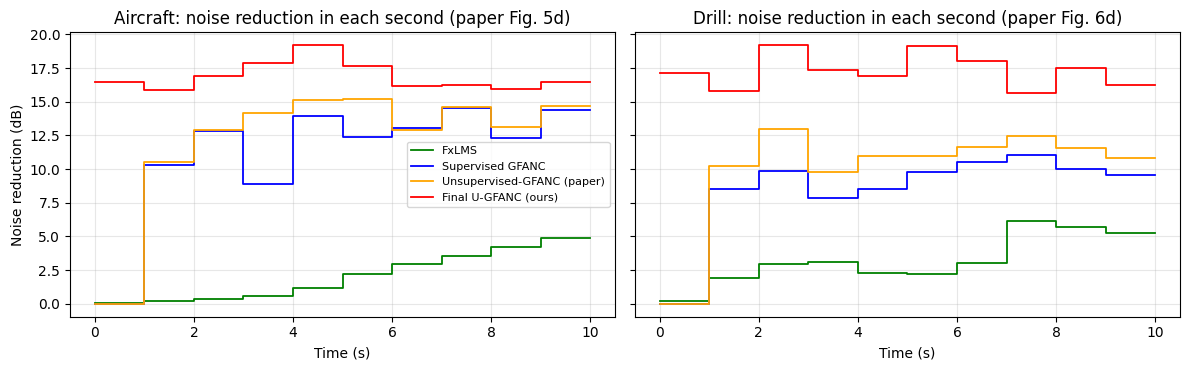

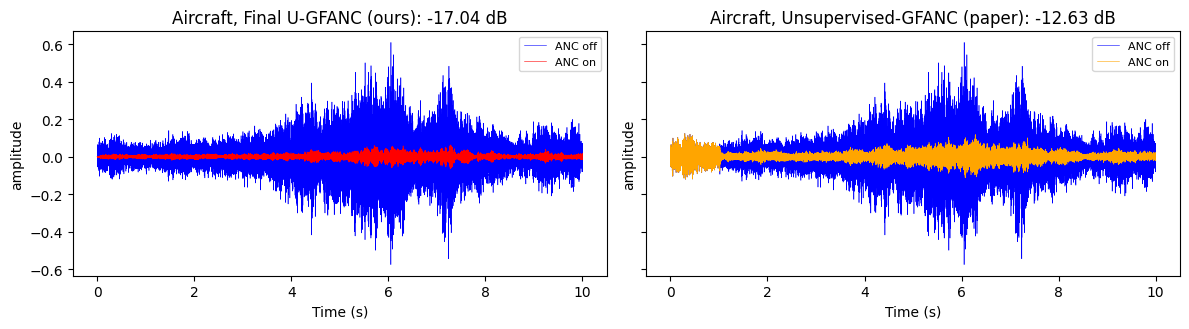

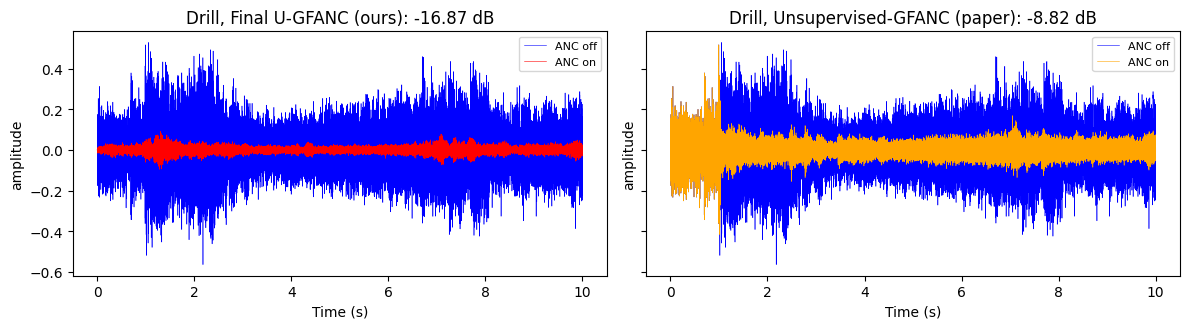

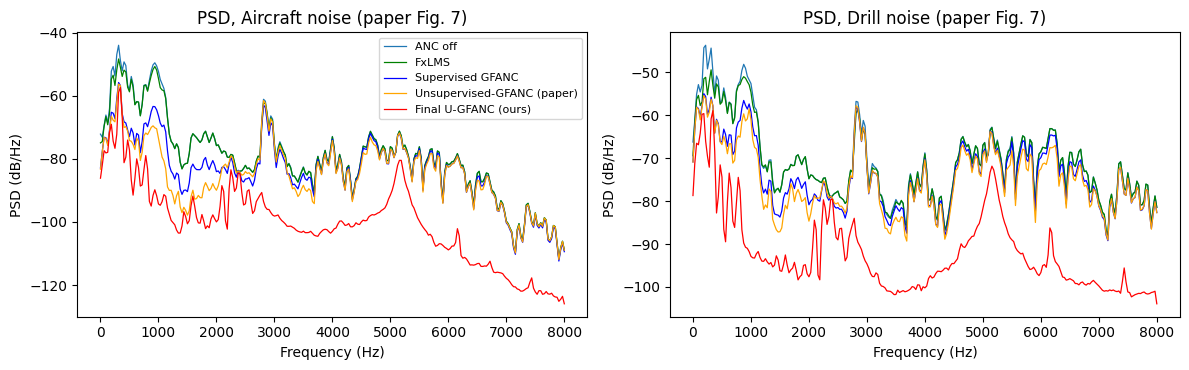

In [26]:
# ---- figures (at most two panels each)
PAPER_M = [
    ("FxLMS (μ = 1e-4)", "FxLMS", "green"),
    ("Supervised GFANC (FxLMS)", "Supervised GFANC", "blue"),
    ("U-GFANC (FxLMS)", "Unsupervised-GFANC (paper)", "orange"),
    (OURS, "Final U-GFANC (ours)", "red"),
]


def per_second_nr(e, d):
    return [
        10
        * np.log10(np.sum(d[i * FS : (i + 1) * FS] ** 2) / max(np.sum(e[i * FS : (i + 1) * FS] ** 2), 1e-30))
        for i in range(len(d) // FS)
    ]


# the paper's Figs. 5(d) / 6(d): averaged noise reduction in each second
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for a, c in zip(ax, ["Aircraft", "Drill"]):
    d = T2E[(c, "d")]
    for k, lab, col in PAPER_M:
        nr = per_second_nr(T2E[(c, k)][: len(d)], d)
        a.step(np.arange(len(nr) + 1), [nr[0]] + nr, where="pre", color=col, lw=1.3, label=lab)
    a.set_title(f"{c}: noise reduction in each second (paper Fig. {5 if c == 'Aircraft' else 6}d)")
    a.set_xlabel("Time (s)")
    a.grid(alpha=0.3)
ax[0].set_ylabel("Noise reduction (dB)")
ax[0].legend(fontsize=8)
savefig("fig_nr_per_second")

# the paper's Figs. 5 / 6 (a): waveforms, ours vs the paper's model
for c in ["Aircraft", "Drill"]:
    d = T2E[(c, "d")]
    t = np.arange(len(d)) / FS
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
    for a, (k, lab, col) in zip(ax, [PAPER_M[3], PAPER_M[2]]):
        a.plot(t, d, color="blue", lw=0.4, label="ANC off")
        a.plot(t, T2E[(c, k)][: len(d)], color=col, lw=0.4, label="ANC on")
        a.set_title(f"{c}, {lab}: {T2[(c, k)]:.2f} dB")
        a.set_xlabel("Time (s)")
        a.set_ylabel("amplitude")
        a.legend(fontsize=8)
    savefig(f"fig_waveforms_{c.lower()}")

# the paper's Fig. 7: PSD
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, c in zip(ax, ["Aircraft", "Drill"]):
    f, p = welch(T2E[(c, "d")], FS, nperseg=512)
    a.plot(f, 10 * np.log10(p + 1e-20), color="C0", lw=0.9, label="ANC off")
    for k, lab, col in PAPER_M:
        f, p = welch(T2E[(c, k)], FS, nperseg=512)
        a.plot(f, 10 * np.log10(p + 1e-20), color=col, lw=0.9, label=lab)
    a.set_title(f"PSD, {c} noise (paper Fig. 7)")
    a.set_xlabel("Frequency (Hz)")
    a.set_ylabel("PSD (dB/Hz)")
ax[0].legend(fontsize=8)
savefig("fig_psd")

## 7.3 All test sets

| Test set | What it is | How it is scored |
|---|---|---|
| **GFANC synthetic, per file** | 2,000 test files | the paper's protocol: the filter chosen from a file is used on that same file |
| **Switching every 1 s** | 10-s synthetic streams; the band changes every second | real-time |
| **ESC-50 steady** | real sustained noise (fold 5) | real-time |
| **ESC-50 abrupt changes** | 10-s streams with a switch or an event at 5 s | real-time |
| **DEMAND** | an unseen dataset | real-time |

**Test: main comparison** (mean NMSE in dB over the three held-out path groups; lower is better). The spread between our 3 seeds is ≤ 0.24 dB

dataset,GFANC synthetic: per file,GFANC synthetic: switching every 1 s,ESC-50 steady,ESC-50 abrupt changes,DEMAND (unseen dataset)
method,,,,,
Supervised GFANC (FxLMS),-9.75,-1.49,-8.49,-7.67,-6.31
U-GFANC (FxLMS),-10.62,-1.78,-9.28,-7.97,-6.58
"U-GFANC (Wiener, modified)",-18.28,-16.11,-17.41,-16.35,-9.77
Fixed Wiener filter (no CNN),-19.09,-20.28,-18.53,-17.7,-10.73
Final U-GFANC (ours),-27.11,-17.25,-19.33,-18.17,-12.39


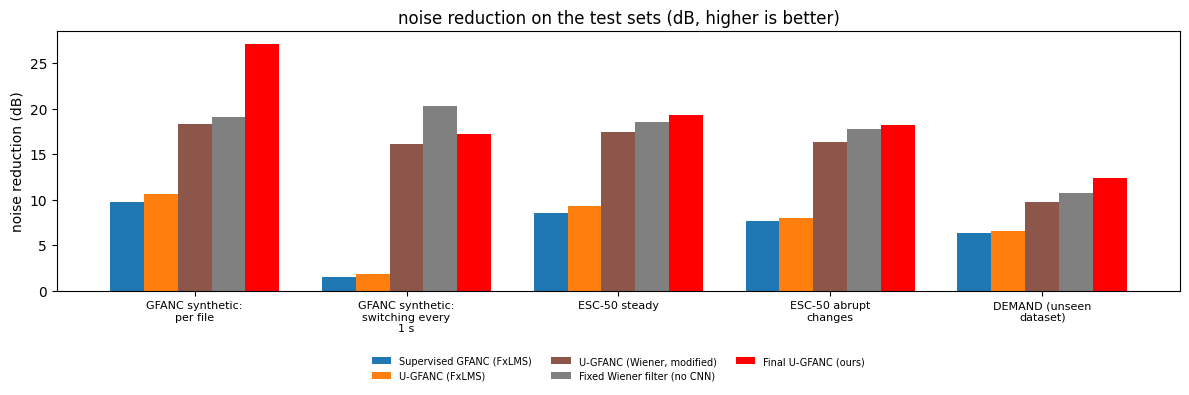

In [27]:
def summary(split, methods, groups=(G_PAPER, G_MEAS, G_GEN)):
    r = RES[(RES.split == split) & RES.group.isin(groups)]
    return r.pivot_table(index="method", columns="dataset", values="nmse", aggfunc="mean").reindex(methods)


COLS = [
    "GFANC synthetic: per file",
    "GFANC synthetic: switching every 1 s",
    "ESC-50 steady",
    "ESC-50 abrupt changes",
    "DEMAND (unseen dataset)",
]
TEST = summary("test", MAIN)[COLS]
sd = SEED_SD.loc["test"].groupby(level="dataset").mean()
display(
    Markdown(
        f"**Test: main comparison** (mean NMSE in dB over the three held-out path groups; lower is better)"
        + (f". The spread between our {len(SEEDS)} seeds is ≤ {sd.max():.2f} dB" if len(SEEDS) > 1 else "")
    )
)
display(dash(TEST))


fig, ax = plt.subplots(figsize=(12, 4.2))
(-TEST).T.plot.bar(ax=ax, width=0.8, color=[MCOL[m] for m in TEST.index])
ax.set_title("noise reduction on the test sets (dB, higher is better)")
ax.set_ylabel("noise reduction (dB)")
ax.set_xlabel("")
ax.set_xticklabels(wrap(COLS, 16), rotation=0, fontsize=8)
legend_below(ax, ncol=3)
savefig("fig_test_comparison")

## 7.4 Robustness on real noise
Worst 10 % = the 90th-percentile stream NMSE; louder windows = the share of 0.25-s windows where ANC added noise;
NR = noise reduction in the first 100 ms after a change.

In [28]:
# ---- robustness (test, real noise): worst decile, amplification, reduction right after a change, path drift
rt = RES[(RES.split == "test") & RES.method.isin(MAIN)]
real = rt[
    rt.dataset.isin(["ESC-50 steady", "ESC-50 abrupt changes", "DEMAND (unseen dataset)"])
    & rt.group.isin(list(GROUPS))
]
ROB = pd.DataFrame(
    {
        "worst 10 % NMSE (real noise)": real.groupby("method").worst10.mean(),
        "amplifying 0.25-s windows % (real noise)": real.groupby("method").amplifying_pct.mean(),
        "NR 0-100 ms after a change (dB)": rt[rt.dataset == "ESC-50 abrupt changes"]
        .groupby("method")
        .nr_0_100ms.mean(),
    }
).reindex(MAIN)
ROB_DONE = True
display(Markdown("**Robustness on real noise (test)**"))
display(dash(ROB))

**Robustness on real noise (test)**

,worst 10 % NMSE (real noise),amplifying 0.25-s windows % (real noise),NR 0-100 ms after a change (dB)
method,,,
Supervised GFANC (FxLMS),-2.44,3.06,7.31
U-GFANC (FxLMS),-1.89,3.83,7.99
"U-GFANC (Wiener, modified)",-6.04,2.18,16.42
Fixed Wiener filter (no CNN),-6.12,2.25,17.44
Final U-GFANC (ours),-7.27,1.8,17.54


## 7.5 What the CNN learned
Left: the weights over the 66 filters during a stream with a sudden change at 5 s. Right: how peaked the weights are
(1 = the CNN picks a single filter).

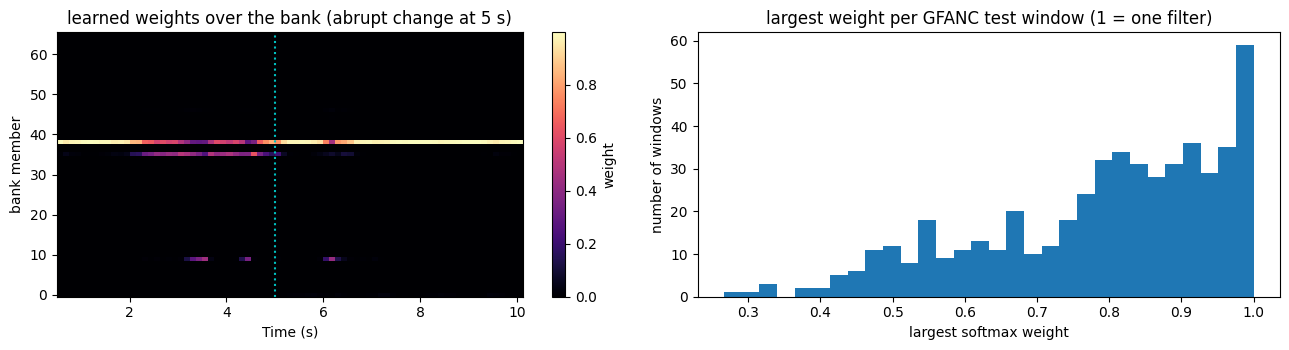

In [29]:
# what the CNN learned: soft weights over time (an abrupt-change stream) and how "peaked" they are
X = DATA["test"]["ESC-50 abrupt changes"]
pv = torch.tensor([vent], device=dev)
with torch.no_grad():
    _, g = gen_filters(
        M[SEEDS[0]].net, torch.tensor(X[:1], device=dev).unfold(-1, WIN, HOP_EVAL), T_BANK["proto"][pv]
    )
    gs = (
        M[SEEDS[0]]
        .net(p2p(torch.tensor(PERFILE["test"][:512], device=dev)[:, None, :WIN]))
        .float()
        .cpu()
        .numpy()
    )
g = g[0].cpu().numpy()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
_im = ax[0].imshow(
    g.T,
    aspect="auto",
    origin="lower",
    extent=[WIN / FS, (WIN + len(g) * HOP_EVAL) / FS, -0.5, g.shape[1] - 0.5],
    cmap="magma",
)
fig.colorbar(_im, ax=ax[0], label="weight")
ax[0].axvline(5, color="c", ls=":")
ax[0].set_title("learned weights over the bank (abrupt change at 5 s)")
ax[0].set_xlabel("Time (s)")
ax[0].set_ylabel("bank member")
ax[1].hist(gs.max(1), 30)
ax[1].set_title("largest weight per GFANC test window (1 = one filter)")
ax[1].set_xlabel("largest softmax weight")
ax[1].set_ylabel("number of windows")
savefig("fig_learned_weights")

# 8. Multi-path study (new rooms)

- **Per room group:** the mean over the three real-noise test sets, for each group of unseen rooms.
- **Transfer:** the 13 real measured rooms (the paper's path + 12 PANDAR), compared room by room. For each new room
  only the filter bank is recomputed; the CNN stays the same.

## 8.1 Per room group

**Multi-path benchmark (test):** mean NMSE in dB over the three real-noise datasets, per path group

group,paper's measured path,new measured paths (12),new generated paths (40)
method,,,
Supervised GFANC (FxLMS),-9.12,-7.88,-5.47
U-GFANC (FxLMS),-9.44,-8.49,-5.91
"U-GFANC (Wiener, modified)",-16.88,-14.91,-11.72
Fixed Wiener filter (no CNN),-17.38,-15.54,-14.04
Final U-GFANC (ours),-18.42,-16.31,-15.16
Final w/o multi-path training (paper's path only),-18.32,-15.51,-14.83


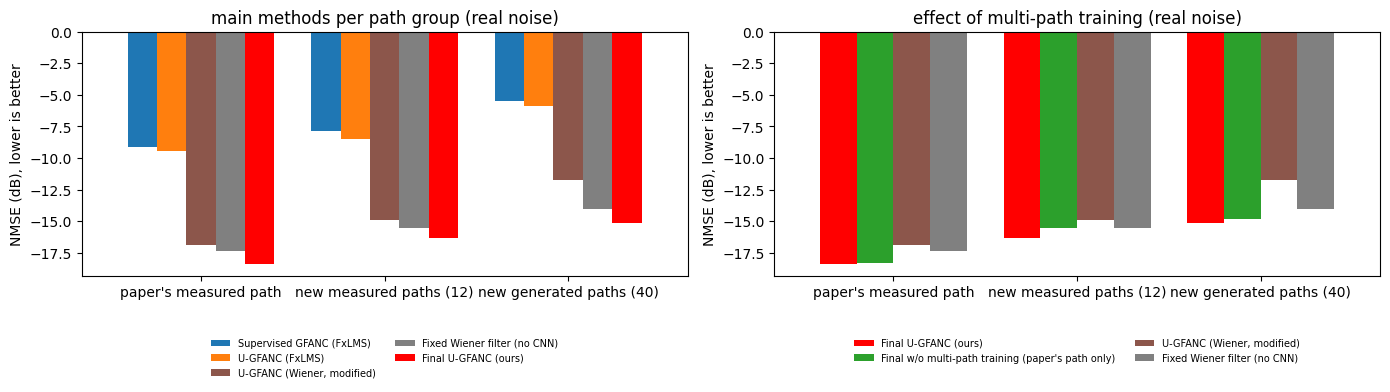

In [30]:
REAL = ["ESC-50 steady", "ESC-50 abrupt changes", "DEMAND (unseen dataset)"]
MP_METHODS = MAIN + [ABL_NAMES["F-multipath"]]
rr = RES[(RES.split == "test") & RES.dataset.isin(REAL) & RES.group.isin(list(GROUPS))]
MPB = rr.pivot_table(index="method", columns="group", values="nmse", aggfunc="mean").reindex(
    index=MP_METHODS, columns=list(GROUPS)
)
display(
    Markdown(
        "**Multi-path benchmark (test):** mean NMSE in dB over the three real-noise datasets, per path group"
    )
)
display(dash(MPB))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
MPB.loc[MAIN].T.plot.bar(ax=ax[0], width=0.8, color=[MCOL[m] for m in MAIN])
ax[0].set_title("main methods per path group (real noise)")
ax[0].set_ylabel("NMSE (dB), lower is better")
ax[0].set_xlabel("")
ax[0].tick_params(axis="x", rotation=0)
legend_below(ax[0], ncol=2)
MPB.loc[
    [OURS, ABL_NAMES["F-multipath"], "U-GFANC (Wiener, modified)", "Fixed Wiener filter (no CNN)"]
].T.plot.bar(ax=ax[1], width=0.8, color=["red", "C2", MCOL["U-GFANC (Wiener, modified)"], "gray"])
ax[1].set_title("effect of multi-path training (real noise)")
ax[1].set_ylabel("NMSE (dB), lower is better")
ax[1].set_xlabel("")
ax[1].tick_params(axis="x", rotation=0)
legend_below(ax[1], ncol=2)
savefig("fig_multipath")

## 8.2 Transfer to the 13 measured rooms

In [31]:
TRANS = []
for dname in ["ESC-50 steady", "DEMAND (unseen dataset)"]:
    for g in (G_PAPER, G_MEAS):
        pidx = PIDX[("test", dname, g)]
        for mname in ["U-GFANC (FxLMS)", "U-GFANC (Wiener, modified)", "Fixed Wiener filter (no CNN)", OURS]:
            nm = PSTREAM[("test", dname, g, mname)]
            for pth in np.unique(pidx):
                TRANS.append(
                    dict(dataset=dname, path=PNAME[pth], method=mname, nmse=float(nm[pidx == pth].mean()))
                )
TRANS = pd.DataFrame(TRANS)
TP = TRANS.pivot_table(index=["dataset", "path"], columns="method", values="nmse")
TSUM = pd.DataFrame(
    {
        d: {
            "paths": len(TP.loc[d]),
            "U-GFANC (FxLMS), mean": TP.loc[d]["U-GFANC (FxLMS)"].mean(),
            "U-GFANC (Wiener, modified), mean": TP.loc[d]["U-GFANC (Wiener, modified)"].mean(),
            "Fixed Wiener filter (no CNN), mean": TP.loc[d]["Fixed Wiener filter (no CNN)"].mean(),
            "Final U-GFANC (ours), mean": TP.loc[d][OURS].mean(),
            "paths where ours beats the paper": int((TP.loc[d][OURS] < TP.loc[d]["U-GFANC (FxLMS)"]).sum()),
            "paths where ours beats U-GFANC (Wiener, modified)": int(
                (TP.loc[d][OURS] < TP.loc[d]["U-GFANC (Wiener, modified)"]).sum()
            ),
            "paths where ours beats the fixed filter": int(
                (TP.loc[d][OURS] < TP.loc[d]["Fixed Wiener filter (no CNN)"]).sum()
            ),
        }
        for d in ["ESC-50 steady", "DEMAND (unseen dataset)"]
    }
)
display(
    Markdown(
        "**Transfer to 13 unseen measured paths** (mean NMSE over the paths, and on how many paths ours is better)"
    )
)
display(
    pd.DataFrame(
        {
            c: {k: (f"{int(v)}" if k.startswith("paths") else f"{v:.2f}") for k, v in TSUM[c].items()}
            for c in TSUM
        }
    )
)

**Transfer to 13 unseen measured paths** (mean NMSE over the paths, and on how many paths ours is better)

,ESC-50 steady,DEMAND (unseen dataset)
paths,13,13
"U-GFANC (FxLMS), mean",-10.60,-6.01
"U-GFANC (Wiener, modified), mean",-20.00,-7.10
"Fixed Wiener filter (no CNN), mean",-21.03,-6.85
"Final U-GFANC (ours), mean",-22.13,-7.57
paths where ours beats the paper,13,13
"paths where ours beats U-GFANC (Wiener, modified)",13,12
paths where ours beats the fixed filter,13,13


# 9. Sudden noise changes (abrupt-noise study)

## 9.1 Showcase: one change at 10 s

On the paper's measured path. Two streams:
- **synthetic:** band noise from 300–700 Hz to 1,300–2,000 Hz;
- **real:** the paper's Drill recording, then its Aircraft recording.

Scored before (1–10 s), in the 1st second after (10–11 s), and after (10–20 s).

**Synthetic: 300–700 Hz → 1300–2000 Hz** (paper's measured path): NMSE in dB, lower is better

,before (1–10 s),1st s after (10–11 s),after (10–20 s)
FxLMS (μ = 1e-4),-11.90,-1.46,-5.54
Supervised GFANC (FxLMS),-15.97,-0.92,-10.40
U-GFANC (FxLMS),-16.27,-19.74,-21.31
"U-GFANC (Wiener, modified)",-17.06,-22.62,-25.97
Fixed Wiener filter (no CNN),-17.06,-22.66,-26.04
Final U-GFANC (ours),-17.05,-23.06,-27.06


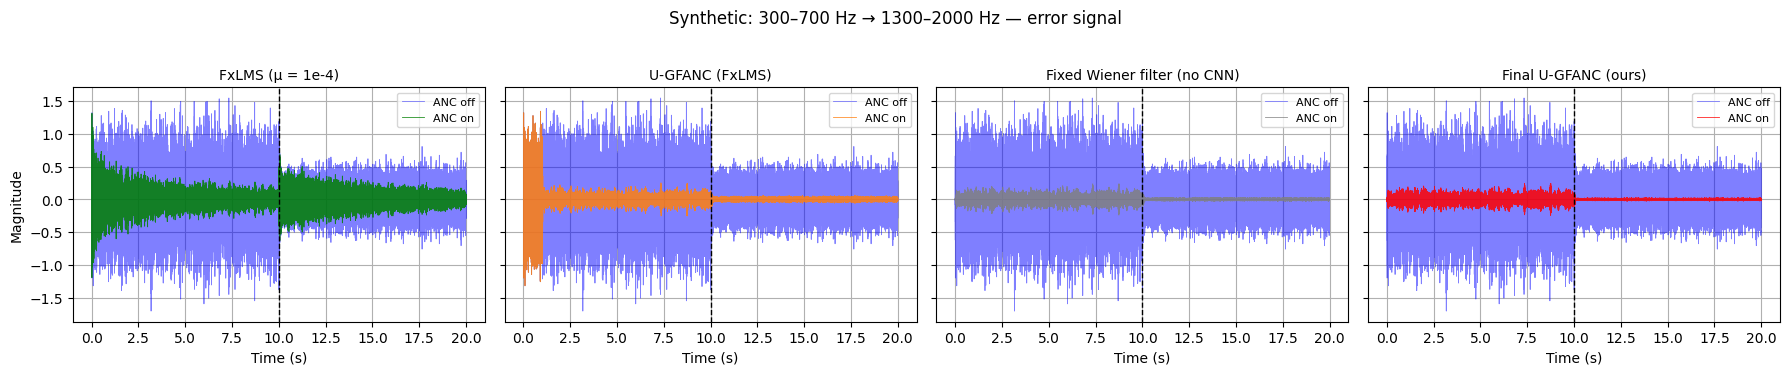

**Real: Drill → Aircraft** (paper's measured path): NMSE in dB, lower is better

,before (1–10 s),1st s after (10–11 s),after (10–20 s)
FxLMS (μ = 1e-4),-3.41,-5.36,-5.32
Supervised GFANC (FxLMS),-9.58,-10.10,-12.78
U-GFANC (FxLMS),-11.34,-12.36,-14.17
"U-GFANC (Wiener, modified)",-15.09,-13.93,-16.74
Fixed Wiener filter (no CNN),-15.22,-14.04,-16.82
Final U-GFANC (ours),-16.85,-14.91,-16.99


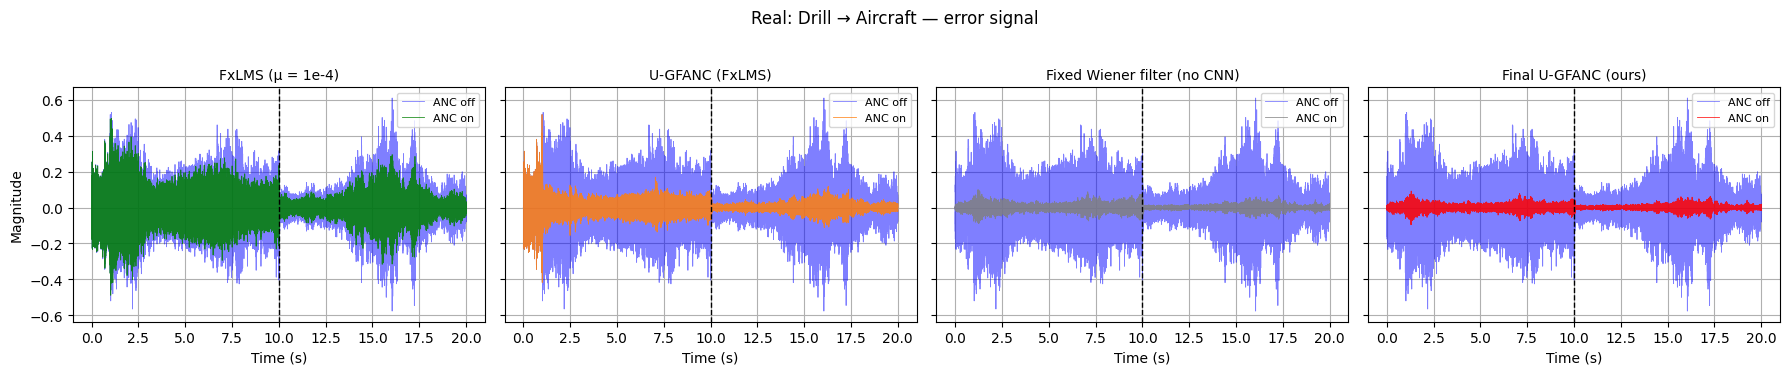

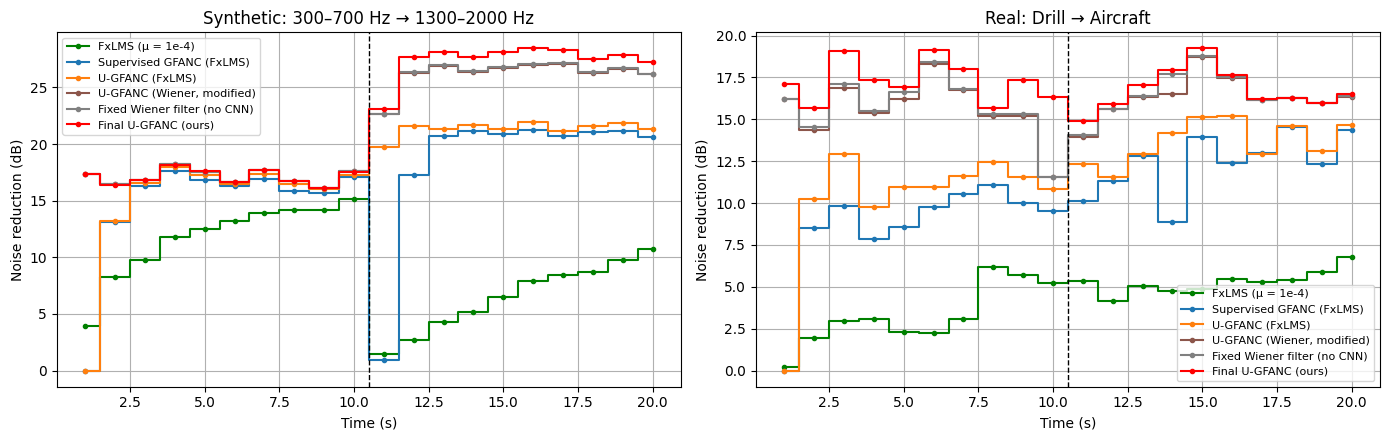

In [32]:
def band_noise(f1, f2, seconds, seed, target_std):
    """White noise through a 1024-tap firwin band-pass filter, scaled to a given standard deviation."""
    rng_b = np.random.default_rng(seed)
    h = firwin(1024, [f1, f2], pass_zero="bandpass", fs=FS)
    y = lfilter(h, 1, rng_b.standard_normal(seconds * FS + 1024))[1024:]
    return y / np.std(y) * target_std


AS_T = 10  # change time (s)
_ref = np.std(CLIPS["Drill"][: AS_T * FS])  # the level of the paper's recordings
AS_CASES = {
    "Synthetic: 300\u2013700 Hz \u2192 1300\u20132000 Hz": np.r_[
        band_noise(300, 700, AS_T, 1, _ref), band_noise(1300, 2000, AS_T, 2, _ref)
    ],
    "Real: Drill \u2192 Aircraft": np.r_[CLIPS["Drill"][: AS_T * FS], CLIPS["Aircraft"][: AS_T * FS]],
}
AS_FX = "FxLMS (\u03bc = 1e-4)"
AS_GF = [
    "Supervised GFANC (FxLMS)",
    "U-GFANC (FxLMS)",
    "U-GFANC (Wiener, modified)",
    "Fixed Wiener filter (no CNN)",
]
AS_METHODS = [AS_FX] + AS_GF + [OURS]
AS_COL = {
    AS_FX: "green",
    "Supervised GFANC (FxLMS)": "C0",
    "U-GFANC (FxLMS)": "C1",
    "U-GFANC (Wiener, modified)": MCOL["U-GFANC (Wiener, modified)"],
    "Fixed Wiener filter (no CNN)": "gray",
    OURS: "red",
}
AS_WAVE = [AS_FX, "U-GFANC (FxLMS)", "Fixed Wiener filter (no CNN)", OURS]  # error-signal panels
AS_STATS = ["before (1\u201310 s)", "1st s after (10\u201311 s)", "after (10\u201320 s)"]


def as_run(X, pidx, with_fxlms=True):
    """{method: (e, d)} for streams X [N, T] on paths pidx; our three seeds are kept separately."""
    out = {}
    if with_fxlms:
        out[AS_FX] = fx_run(X, pidx, 1e-4)
    chunk = CFG["eval_chunk"]
    CFG["eval_chunk"] = max(1, chunk // 4)  # 20-s streams: 4x fewer streams per GPU batch
    try:
        for mname in AS_GF + SEEDS:
            out[mname] = M[mname].run(X.astype(np.float32), pidx)
    finally:
        CFG["eval_chunk"] = chunk
    return out


def as_stats(e, d):  # mean NMSE (dB) over the streams in each time range
    return dict(
        zip(
            AS_STATS,
            [
                float(nmse_db(e, d, FS, AS_T * FS).mean()),
                float(nmse_db(e, d, AS_T * FS, (AS_T + 1) * FS).mean()),
                float(nmse_db(e, d, AS_T * FS, None).mean()),
            ],
        )
    )


def per_sec_nr(e, d):  # [N, T] -> mean noise reduction (dB) in each second
    n = e.shape[-1] // FS
    ee = np.asarray(e[..., : n * FS], np.float64).reshape(len(e), n, FS)
    dd = np.asarray(d[..., : n * FS], np.float64).reshape(len(d), n, FS)
    with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
        nr = 10 * np.log10(np.sum(dd**2, -1) / np.maximum(np.sum(ee**2, -1), 1e-30))
    return np.nan_to_num(np.clip(nr, -20, None), nan=-20).mean(0)


def as_collect(out):
    """Per-method stats and per-second NR; 'ours' = mean of the three seeds."""
    st = {m: as_stats(*out[m]) for m in out}
    nr = {m: per_sec_nr(*out[m]) for m in out}
    st[OURS] = {k: float(np.mean([st[s_][k] for s_ in SEEDS])) for k in AS_STATS}
    nr[OURS] = np.mean([nr[s_] for s_ in SEEDS], 0)
    return st, nr


# ---- (1) the paper's measured path, all methods
_vent = PNAME.index("vent")
AS_TAB, AS_NR, AS_SIG = {}, {}, {}
t_ax = np.arange(2 * AS_T * FS) / FS
for case, x in AS_CASES.items():
    out = as_run(x[None].astype(np.float64), np.array([_vent]))
    st, nr = as_collect(out)
    AS_TAB[case] = pd.DataFrame({m: st[m] for m in AS_METHODS}).T[AS_STATS]
    AS_NR[case] = nr
    AS_SIG[case] = {m: (out[m][0][0], out[m][1][0]) for m in AS_METHODS if m != OURS}
    AS_SIG[case][OURS] = (out[SEEDS[0]][0][0], out[SEEDS[0]][1][0])
    display(Markdown(f"**{case}** (paper's measured path): NMSE in dB, lower is better"))
    display(AS_TAB[case].round(2))
    # error signal of each method: ANC off (disturbance) vs ANC on (residual), one panel per method
    fig, ax = plt.subplots(1, len(AS_WAVE), figsize=(18, 3.6), sharey=True)
    for a, m in zip(ax, AS_WAVE):
        e, d = AS_SIG[case][m]
        a.plot(t_ax, d, color="blue", alpha=0.5, lw=0.6, label="ANC off")
        a.plot(
            t_ax,
            np.clip(e, -3 * np.abs(d).max(), 3 * np.abs(d).max()),
            color=AS_COL[m],
            alpha=0.85,
            lw=0.6,
            label="ANC on",
        )
        a.axvline(AS_T, color="k", ls="--", lw=1)
        a.set_title(m, fontsize=10)
        a.set_xlabel("Time (s)")
        a.grid(True)
        a.legend(fontsize=8, loc="upper right")
    ax[0].set_ylabel("Magnitude")
    fig.suptitle(f"{case} \u2014 error signal", y=1.03)
    savefig("fig_abrupt_wave_" + ("synth" if case.startswith("Synthetic") else "real"))

# per-second noise reduction for both cases
sec = np.arange(1, 2 * AS_T + 1)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, case in zip(ax, AS_CASES):
    for m in AS_METHODS:
        a.step(sec, AS_NR[case][m], where="mid", marker="o", ms=3, color=AS_COL[m], label=m)
    a.axvline(AS_T + 0.5, color="k", ls="--", lw=1)
    a.set_title(case)
    a.set_xlabel("Time (s)")
    a.set_ylabel("Noise reduction (dB)")
    a.grid(True)
    a.legend(fontsize=8)
savefig("fig_abrupt_showcase_nr")

## 9.2 The same showcase in every group of unseen rooms
The paper's path, 12 measured rooms and 40 generated rooms.

**NMSE 1st s after (10–11 s), per path group** (dB, lower is better; mean over the paths of each group)

method                                                         Supervised GFANC (FxLMS)  U-GFANC (FxLMS)  U-GFANC (Wiener, modified)  Fixed Wiener filter (no CNN)  Final U-GFANC (ours)
case                                 group                                                                                                                                              
Real: Drill → Aircraft               new generated paths (40)                     -4.18            -6.23                      -10.15                        -12.39                -13.72
                                     new measured paths (12)                      -2.03           -10.69                      -12.47                        -12.48                -12.33
                                     paper's measured path                       -10.10           -12.36                      -13.93                        -14.04                -14.91
Synthetic: 300–700 Hz → 1300–2000 Hz new generated paths (40)                     -0.52           -17.83                      -27.73                        -29.51                -30.33
                                     new measured paths (12)                      -3.18            -7.27                      -22.98                        -23.00                -26.79
                                     paper's measured path                        -0.92           -19.74                      -22.62                        -22.66                -23.06

**NMSE after (10–20 s), per path group** (dB, lower is better; mean over the paths of each group)

method                                                         Supervised GFANC (FxLMS)  U-GFANC (FxLMS)  U-GFANC (Wiener, modified)  Fixed Wiener filter (no CNN)  Final U-GFANC (ours)
case                                 group                                                                                                                                              
Real: Drill → Aircraft               new generated paths (40)                     -6.24            -7.06                      -12.16                        -14.16                -15.38
                                     new measured paths (12)                      -9.12           -12.74                      -13.97                        -13.98                -13.60
                                     paper's measured path                       -12.78           -14.17                      -16.74                        -16.82                -16.99
Synthetic: 300–700 Hz → 1300–2000 Hz new generated paths (40)                     -7.26           -18.03                      -28.88                        -31.94                -35.91
                                     new measured paths (12)                      -1.51            -1.75                      -24.69                        -24.95                -35.16
                                     paper's measured path                       -10.40           -21.31                      -25.97                        -26.04                -27.06

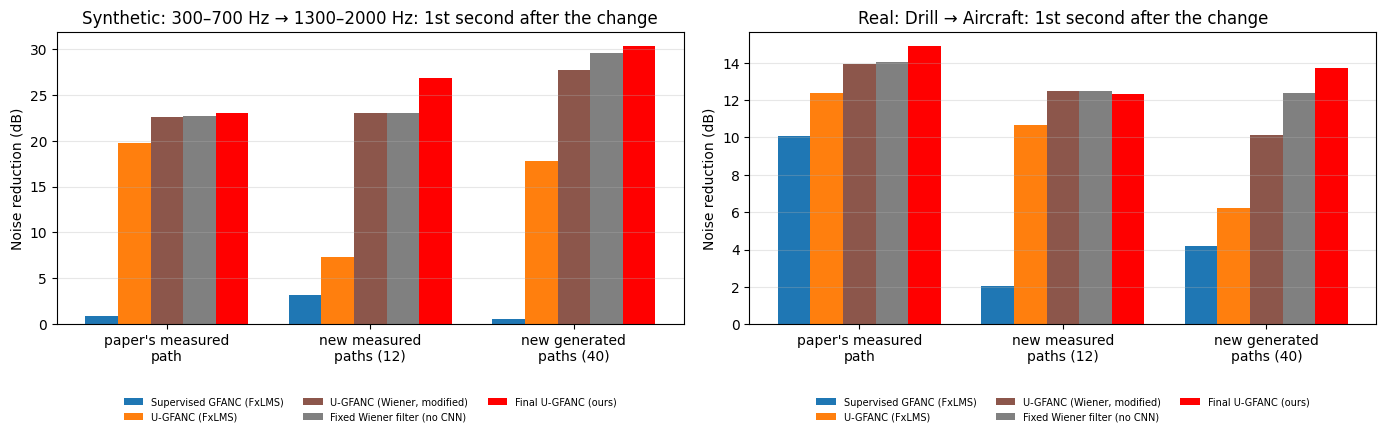

**Summary (paper's measured path), 1st second after the change.** Synthetic: 300–700 Hz → 1300–2000 Hz: FxLMS -1.5 dB, U-GFANC (FxLMS) -19.7 dB, fixed Wiener filter -22.7 dB, ours -23.1 dB. Real: Drill → Aircraft: -5.4 / -12.4 / -14.0 / -14.9 dB (same order).

In [33]:
AS_PATH, AS_PNR = [], {}
for case, x in AS_CASES.items():
    for gname, gidx in GROUPS.items():
        gidx = np.asarray(gidx)
        out = as_run(np.repeat(x[None].astype(np.float64), len(gidx), 0), gidx, with_fxlms=False)
        st, nr = as_collect(out)
        for m in AS_GF + [OURS]:
            AS_PATH.append(dict(case=case, group=gname, method=m, **st[m]))
            AS_PNR[(case, gname, m)] = nr[m]
AS_PATH = pd.DataFrame(AS_PATH)
for col in AS_STATS[1:]:
    display(
        Markdown(f"**NMSE {col}, per path group** (dB, lower is better; mean over the paths of each group)")
    )
    display(
        AS_PATH.pivot_table(index=["case", "group"], columns="method", values=col)
        .reindex(columns=AS_GF + [OURS])
        .round(2)
    )

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
PM = AS_GF + [OURS]
w_ = 0.8 / len(PM)
gl = list(GROUPS)
for a, case in zip(ax, AS_CASES):
    t = AS_PATH[AS_PATH.case == case]
    for j, m in enumerate(PM):
        v = [-t[(t.group == g) & (t.method == m)][AS_STATS[1]].iloc[0] for g in gl]
        a.bar(np.arange(len(gl)) + j * w_, v, w_, color=AS_COL[m], label=m)
    a.set_xticks(np.arange(len(gl)) + w_ * (len(PM) - 1) / 2)
    a.set_xticklabels(wrap(gl, 16))
    a.set_title(f"{case}: 1st second after the change")
    a.set_ylabel("Noise reduction (dB)")
    a.grid(axis="y", alpha=0.3)
legend_below(ax[0], ncol=3)
legend_below(ax[1], ncol=3)
savefig("fig_abrupt_paths_bars")

_c1, _c2 = list(AS_CASES)
_t1, _t2 = AS_TAB[_c1], AS_TAB[_c2]
display(
    Markdown(
        f"**Summary (paper's measured path), 1st second after the change.** {_c1}: FxLMS {_t1.loc[AS_FX, AS_STATS[1]]:.1f} dB, "
        f"U-GFANC (FxLMS) {_t1.loc['U-GFANC (FxLMS)', AS_STATS[1]]:.1f} dB, fixed Wiener filter "
        f"{_t1.loc['Fixed Wiener filter (no CNN)', AS_STATS[1]]:.1f} dB, ours {_t1.loc[OURS, AS_STATS[1]]:.1f} dB. {_c2}: "
        f"{_t2.loc[AS_FX, AS_STATS[1]]:.1f} / {_t2.loc['U-GFANC (FxLMS)', AS_STATS[1]]:.1f} / "
        f"{_t2.loc['Fixed Wiener filter (no CNN)', AS_STATS[1]]:.1f} / {_t2.loc[OURS, AS_STATS[1]]:.1f} dB (same order)."
    )
)

## 9.3 Benchmark: every ESC-50 test stream with a change at 5 s

The change is a switch to another noise, or an event on top of the ongoing noise, with a level jump of −6 to +12 dB.
- **NR curve:** noise reduction in 100-ms windows around the change.
- **NR right after:** noise reduction in the first 0.5 s, for each level jump.

**Abrupt-change benchmark (test):** noise reduction in dB (higher is better) before and after the change

,NR 0.5 s before the change,NR 0-0.5 s after,NR 0.5-3 s after,"NR 0-0.5 s after, noise switch","NR 0-0.5 s after, event onset"
Supervised GFANC (FxLMS),9.19,7.61,8.22,7.59,7.66
U-GFANC (FxLMS),10.04,8.27,8.75,8.29,8.23
"U-GFANC (Wiener, modified)",17.54,16.68,16.78,16.39,17.3
Fixed Wiener filter (no CNN),18.47,17.82,18.07,17.73,18.02
Final U-GFANC (ours),19.24,18.07,18.76,17.9,18.42
Final w/o ESC-50 & abrupt changes (synthetic noise only),16.05,14.46,15.54,14.37,14.65


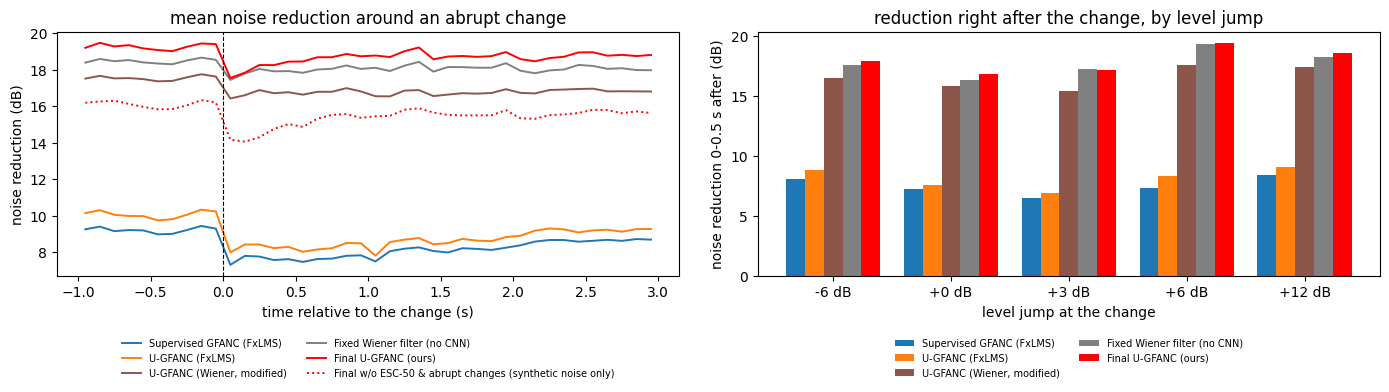

In [34]:
AB_METHODS = MAIN + [ABL_NAMES["F-esc"]]
tm_ = TR_META["test"]
nrw = {m: np.concatenate([NRW[(g, m)] for g in GROUPS]) for m in AB_METHODS}
meta_rep = pd.concat([tm_] * len(GROUPS), ignore_index=True)
after = {m: v[:, 10:15].mean(1) for m, v in nrw.items()}  # 0-0.5 s after the change (windows 10-14)
ABT = pd.DataFrame(
    {
        "NR 0.5 s before the change": {m: v[:, 5:10].mean() for m, v in nrw.items()},
        "NR 0-0.5 s after": {m: a.mean() for m, a in after.items()},
        "NR 0.5-3 s after": {m: v[:, 15:].mean() for m, v in nrw.items()},
        **{
            f"NR 0-0.5 s after, {k}": {m: a[(meta_rep.kind == k).values].mean() for m, a in after.items()}
            for k in ["noise switch", "event onset"]
        },
    }
).reindex(AB_METHODS)
display(
    Markdown(
        "**Abrupt-change benchmark (test):** noise reduction in dB (higher is better) before and after the change"
    )
)
display(dash(ABT))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
tt = (np.arange(nrw[OURS].shape[1]) * W100 + W100 / 2) / FS - 1.0
for m, col, ls in [
    ("Supervised GFANC (FxLMS)", MCOL["Supervised GFANC (FxLMS)"], "-"),
    ("U-GFANC (FxLMS)", MCOL["U-GFANC (FxLMS)"], "-"),
    ("U-GFANC (Wiener, modified)", MCOL["U-GFANC (Wiener, modified)"], "-"),
    ("Fixed Wiener filter (no CNN)", "gray", "-"),
    (OURS, "red", "-"),
    (ABL_NAMES["F-esc"], "red", ":"),
]:
    ax[0].plot(tt, nrw[m].mean(0), color=col, ls=ls, lw=1.4, label=m)
ax[0].axvline(0, color="k", ls="--", lw=0.8)
ax[0].set_xlabel("time relative to the change (s)")
ax[0].set_ylabel("noise reduction (dB)")
ax[0].set_title("mean noise reduction around an abrupt change")
legend_below(ax[0], ncol=2)
lv = sorted(meta_rep.jump_db.unique())
w_ = 0.8 / len(MAIN)
for j, (m, col) in enumerate((m, MCOL[m]) for m in MAIN):
    ax[1].bar(
        np.arange(len(lv)) + j * w_,
        [after[m][(meta_rep.jump_db == l).values].mean() for l in lv],
        w_,
        color=col,
        label=m,
    )
ax[1].set_xticks(np.arange(len(lv)) + w_ * (len(MAIN) - 1) / 2)
ax[1].set_xticklabels([f"{l:+.0f} dB" for l in lv])
ax[1].set_xlabel("level jump at the change")
ax[1].set_ylabel("noise reduction 0-0.5 s after (dB)")
ax[1].set_title("reduction right after the change, by level jump")
legend_below(ax[1], ncol=2)
savefig("fig_abrupt")

## 9.4 Noise reduction over time around one change
One ESC-50 stream on the paper's measured path, in 50-ms windows.

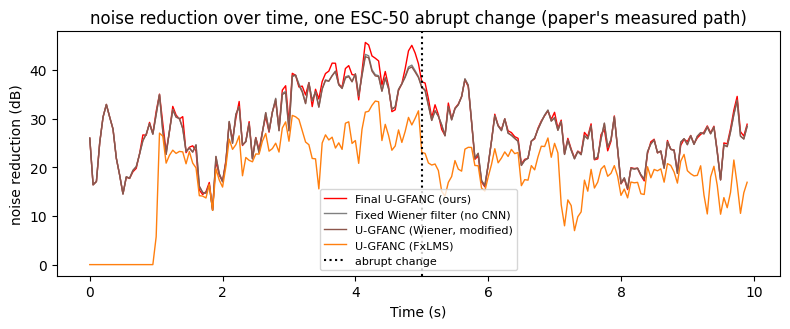

In [35]:
# reduction over time around a change (one abrupt-change stream, paper's measured path)
fig, ax = plt.subplots(figsize=(8, 3.4))
for k, col in [
    (OURS, "red"),
    ("Fixed Wiener filter (no CNN)", "gray"),
    ("U-GFANC (Wiener, modified)", MCOL["U-GFANC (Wiener, modified)"]),
    ("U-GFANC (FxLMS)", MCOL["U-GFANC (FxLMS)"]),
]:
    kk = SEEDS[0] if k == OURS else k
    if kk in CURVE:
        e, d = CURVE[kk]
        nr = [
            10 * np.log10(np.sum(d[i : i + 800] ** 2) / np.sum(e[i : i + 800] ** 2))
            for i in range(0, len(d) - 800, 800)
        ]
        ax.plot(np.arange(len(nr)) * 800 / FS, nr, color=col, lw=1, label=k)
ax.axvline(5, color="k", ls=":", label="abrupt change")
ax.set_title("noise reduction over time, one ESC-50 abrupt change (paper's measured path)")
ax.set_xlabel("Time (s)")
ax.set_ylabel("noise reduction (dB)")
ax.legend(fontsize=8)
savefig("fig_transition")

# 10. Ablation study

Each "Final w/o X" model is retrained from scratch with exactly one change removed, then tested the same way.
**"Real noise"** is the mean of ESC-50 steady, ESC-50 abrupt changes and DEMAND.

**Ablation (test)**: each 'Final w/o X' row is our model retrained from scratch without X

dataset,GFANC synthetic: per file,GFANC synthetic: switching every 1 s,ESC-50 steady,ESC-50 abrupt changes,DEMAND (unseen dataset),mean (all),mean (real noise)
method,,,,,,,
Final U-GFANC (ours),-27.11,-17.25,-19.33,-18.17,-12.39,-18.85,-16.63
Final w/o prototype bank (paper's 15 sub-bands),-18.81,-19.79,-18.53,-17.7,-10.73,-17.11,-15.65
Final w/o multi-path training (paper's path only),-18.46,-19.22,-18.82,-17.87,-11.98,-17.27,-16.22
Final w/o ESC-50 & abrupt changes (synthetic noise only),-27.38,-15.27,-16.13,-14.68,-8.08,-16.31,-12.96
Final w/o causal loss (paper's same-frame loss),-26.51,-17.53,-19.19,-18.01,-12.3,-18.71,-16.5
"U-GFANC (Wiener, modified)",-18.28,-16.11,-17.41,-16.35,-9.77,-15.58,-14.51
Fixed Wiener filter (no CNN),-19.09,-20.28,-18.53,-17.7,-10.73,-17.27,-15.65


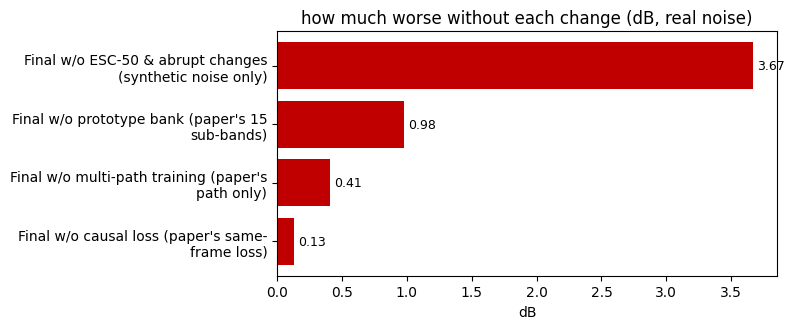

In [36]:
# ---- ablation and the learning check (test)
ABLT = summary("test", ABL)[COLS]
ABLT["mean (all)"] = ABLT.mean(axis=1)
ABLT["mean (real noise)"] = ABLT[["ESC-50 steady", "ESC-50 abrupt changes", "DEMAND (unseen dataset)"]].mean(
    axis=1
)
display(Markdown("**Ablation (test)**: each 'Final w/o X' row is our model retrained from scratch without X"))
display(dash(ABLT))


_drop = pd.Series(
    {
        lab: ABLT.loc[lab, "mean (real noise)"] - ABLT.loc[OURS, "mean (real noise)"]
        for lab in ABL_NAMES.values()
    }
).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(wrap(_drop.index, 40), _drop.values, color="#C00000")
for i, v in enumerate(_drop.values):
    ax.text(v + 0.03, i, f"{v:.2f}", va="center", fontsize=9)
ax.set_title("how much worse without each change (dB, real noise)")
ax.set_xlabel("dB")
savefig("fig_ablation")

## 10.1 Summary: main comparison and ablation on every test set

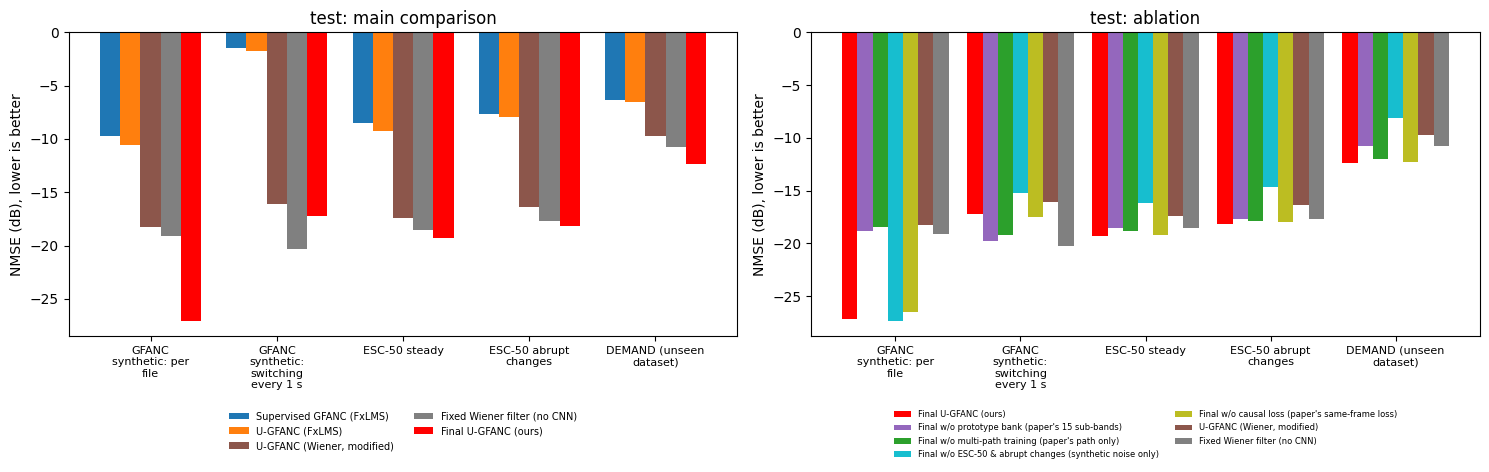

In [37]:
# summary bars: main comparison and ablation on the test datasets
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
TEST.T.plot.bar(ax=ax[0], width=0.8, color=[MCOL[m] for m in TEST.index])
ax[0].set_title("test: main comparison")
ABLT[COLS].T.plot.bar(ax=ax[1], width=0.85, color=[MCOL[m] for m in ABLT.index])
ax[1].set_title("test: ablation")
for a in ax:
    a.set_ylabel("NMSE (dB), lower is better")
    a.set_xlabel("")
    a.set_xticklabels(wrap(COLS, 14), rotation=0, fontsize=8)
legend_below(ax[0], ncol=2)
legend_below(ax[1], ncol=2, fs=6)
savefig("fig_summary")

# 11. Computational cost
Parameters, compute per filter update, latency, and training time.

In [38]:
# ---- computation
def latency_ms(net, L, device, n=100):
    net = copy.deepcopy(net).to(device).eval()
    x = torch.randn(1, 1, L, device=device)
    ts = []
    with torch.no_grad():
        for i in range(n + 10):
            if device.type == "cuda":
                torch.cuda.synchronize()
            t = time.perf_counter()
            net(x)
            if device.type == "cuda":
                torch.cuda.synchronize()
            if i >= 10:
                ts.append((time.perf_counter() - t) * 1000)
    return float(np.median(ts))


torch.set_num_threads(4)
LAT = pd.DataFrame(
    [
        dict(
            model=name,
            parameters=int(sum(p.numel() for p in net.parameters())),
            MAC_per_update_M=round(arch_table(copy.deepcopy(net).to(dev), L).MACs.sum() / 1e6, 1),
            updates_per_s=FS / hop,
            gpu_ms=round(latency_ms(net, L, dev), 2),
            cpu_4threads_ms=round(latency_ms(net, L, torch.device("cpu")), 2),
        )
        for name, net, L, hop in [
            (OURS, M[SEEDS[0]].net, WIN, HOP_EVAL),
            ("U-GFANC (FxLMS)", AUTH["unsup"], FS, FS),
        ]
    ]
)
display(
    Markdown(
        f"**Computation per filter update** (batch 1, median latency; the controller FIR itself costs {TAPS} MAC per sample)"
    )
)
display(LAT)

**Computation per filter update** (batch 1, median latency; the controller FIR itself costs 1024 MAC per sample)

,model,parameters,MAC_per_update_M,updates_per_s,gpu_ms,cpu_4threads_ms
0,Final U-GFANC (ours),217794,118.8,8.0,0.89,3.50
1,U-GFANC (FxLMS),211215,237.6,1.0,1.02,127.54


In [39]:
# training cost of every model
_lab = lambda n: "U-GFANC (Wiener, modified)" if n == "R1_paper" else RUN_LABEL.get(n, n)
TC = pd.DataFrame(
    [
        dict(model=_lab(n), steps=v["steps"], best_step=v["best_step"], train_minutes=round(v["minutes"], 1))
        for n, v in INFO.items()
    ]
    + [
        dict(
            model=f"learning-rate run {lr:g}",
            steps=r["steps"],
            best_step=r["best_step"],
            train_minutes=round(r["minutes"], 1),
        )
        for lr, r in LR_RUNS.items()
    ]
)
display(
    Markdown(
        f"**Training cost** on 2 × Tesla T4 (fp16 CNN, fp32 acoustics), batch {CFG['batch']}: "
        f"{TC.train_minutes.sum() / 60:.1f} GPU-hours in total"
    )
)
display(TC)
print(
    f"inference: {LAT.MAC_per_update_M.iloc[0] * LAT.updates_per_s.iloc[0] / 1e3:.2f} G MAC per second of audio "
    f"for the CNN, plus {TAPS} MAC per sample for the FIR filter"
)

**Training cost** on 2 × Tesla T4 (fp16 CNN, fp32 acoustics), batch 256: 4.3 GPU-hours in total

,model,steps,best_step,train_minutes
0,"U-GFANC (Wiener, modified)",6000,5500,30.7
1,w/o prototype bank,6000,5500,31.8
2,w/o multi-path training,6000,4000,31.6
3,w/o ESC-50 & abrupt changes,6000,3000,31.7
4,w/o causal loss*,6000,5000,17.9
5,Final U-GFANC (seed 0),6000,5500,31.7
6,Final U-GFANC (seed 1),6000,6000,31.7
7,Final U-GFANC (seed 2),6000,6000,31.8
8,learning-rate run 0.0003,1200,1200,6.3
9,learning-rate run 0.001,1200,1000,6.3


inference: 0.95 G MAC per second of audio for the CNN, plus 1024 MAC per sample for the FIR filter


# 12. Novelty

1. **New Wiener filter bank (64 + 2 filters):** the CNN chooses among full filters made for different noise types.
2. **Training on 230 rooms:** the model works in rooms it has never seen.
3. **Real noise with sudden changes (ESC-50):** the model handles real, changing noise.
4. **Real-time control:** it listens to the last 0.5 s, sets a new filter every 0.125 s, and starts with the
   broadband filter, so ANC is never off.

The numbers below come from the tables above.

In [40]:
rn = lambda k: ABLT.loc[k, "mean (real noise)"] - ABLT.loc[OURS, "mean (real noise)"]
pf = lambda k: ABLT.loc[k, "GFANC synthetic: per file"] - ABLT.loc[OURS, "GFANC synthetic: per file"]
dm = lambda k: ABLT.loc[k, "DEMAND (unseen dataset)"] - ABLT.loc[OURS, "DEMAND (unseen dataset)"]
gain_rooms = MPB.loc[ABL_NAMES["F-multipath"], G_MEAS] - MPB.loc[OURS, G_MEAS]
beats = int(TSUM.loc["paths where ours beats the paper", "ESC-50 steady"])
rooms = int(TSUM.loc["paths", "ESC-50 steady"])
txt = f"""
| Change | Gain (test) |
|---|---|
| New Wiener filter bank | {rn(ABL_NAMES['F-bank']):+.2f} dB on real noise, {pf(ABL_NAMES['F-bank']):+.2f} dB per file |
| Training on 230 rooms | {gain_rooms:+.2f} dB in the 12 new measured rooms; {beats} / {rooms} measured rooms beat the paper |
| Real noise with sudden changes | {rn(ABL_NAMES['F-esc']):+.2f} dB on real noise, {dm(ABL_NAMES['F-esc']):+.2f} dB on DEMAND |
| Real-time (causal) training | {rn(ABL_NAMES['F-causal']):+.2f} dB on real noise |

**Table 2 vs the paper:** {t2.loc[OURS, 'Aircraft']:.2f} / {t2.loc[OURS, 'Drill']:.2f} / {t2.loc[OURS, 'Motorbike']:.2f} dB,
against {t2.loc['U-GFANC (FxLMS)', 'Aircraft']:.2f} / {t2.loc['U-GFANC (FxLMS)', 'Drill']:.2f} / {t2.loc['U-GFANC (FxLMS)', 'Motorbike']:.2f} dB
(Aircraft / Drill / Motorbike).
"""
display(Markdown(txt))
(OUT / "results" / "novelty_summary.md").write_text(txt, encoding="utf-8")


| Change | Gain (test) |
|---|---|
| New Wiener filter bank | +0.98 dB on real noise, +8.30 dB per file |
| Training on 230 rooms | +0.80 dB in the 12 new measured rooms; 13 / 13 measured rooms beat the paper |
| Real noise with sudden changes | +3.67 dB on real noise, +4.31 dB on DEMAND |
| Real-time (causal) training | +0.13 dB on real noise |

**Table 2 vs the paper:** -17.04 / -16.87 / -16.68 dB,
against -12.63 / -8.82 / -13.63 dB
(Aircraft / Drill / Motorbike).


472

# 13. Limitations

- **Band switching every 1 s:** when the noise band changes every second, one fixed broadband filter is safer.
- **Gain over a fixed filter:** on broad real noise, the gain over a good fixed Wiener filter is modest.
- **Compute:** 8 filter updates per second cost about 4× the paper's CNN compute (still about 1 ms per update on a GPU).

# 14. Work distribution

| Member | Work |
|---|---|
| Md. Abidur Rahman (2106134) | datasets (GFANC synthetic, ESC-50, DEMAND); dataset visualization and preprocessing; Wiener filter bank and k-means noise types; ablation and supporting studies |
| Emam Mahadi (2106144) | paper reproduction, FxLMS and the authors' models; 1D CNN (the paper's network with a softmax head); hyperparameter tuning; ablation and supporting studies |
| Jawad Al Saad (2106189) | acoustic paths (generated, PANDAR); test benchmarks (new rooms, sudden changes, DEMAND); real-time controller (0.125-s updates, crossfade); ablation and supporting studies |

# 15. Saved files

In [41]:
if (OUT / "gpu_util.csv").exists() and CKPT_SRC is None:
    try:
        gu = pd.read_csv(OUT / "gpu_util.csv", skipinitialspace=True)
        gu["util"] = gu["utilization.gpu [%]"].str.rstrip(" %").astype(float)
        print("average GPU utilisation (training run):", gu.groupby("index").util.mean().round(1).to_dict())
    except Exception as ex:
        print("gpu log unreadable:", ex)
torch.save(
    dict(
        state_dict=M[SEEDS[0]].net.state_dict(),
        model_type="m6_res softmax over prototype-Wiener bank",
        K=CFG["K"],
        rho=CFG["rho"],
        lam=CFG["lam"],
        window=WIN,
        hop=HOP_EVAL,
        fade=FADE,
        latency=LATENCY,
        fs=FS,
        taps=TAPS,
        proto_centroids=PROTO_C,
        proto_r=PROTO_R,
        r_pool=R_POOL,
    ),
    OUT / "updated_gfanc_model.pt",
)
METRICS = dict(
    cfg=CFG,
    arch=ARCH,
    hop_eval=HOP_EVAL,
    test=TEST.round(3).to_dict(),
    table2=t2.round(3).to_dict(),
    multipath=MPB.round(3).to_dict(),
    transfer_paths=TP.round(3).reset_index().to_dict("records"),
    transfer_summary=TSUM.to_dict(),
    robustness=ROB.round(3).to_dict(),
    abrupt_benchmark=ABT.round(3).to_dict(),
    abrupt_showcase={c: t.round(3).to_dict() for c, t in AS_TAB.items()},
    abrupt_showcase_paths=AS_PATH.round(3).to_dict("records"),
    ablation=ABLT.round(3).to_dict(),
    latency=LAT.to_dict("records"),
    tune_bank=TUNE_BANK.to_dict("records"),
    tune_lr=TUNE_LR.to_dict("records"),
    tune_hop=TUNE_HOP.to_dict("records"),
    train={k: {kk: v[kk] for kk in ("best_val_loss", "best_step", "minutes")} for k, v in INFO.items()},
    minutes_total=(time.time() - T0) / 60,
)
(OUT / "metrics.json").write_text(json.dumps(METRICS, indent=1, default=float), encoding="utf-8")
for p in sorted((OUT / "results").glob("*")):
    print(p.name)
log("notebook finished")

fig_ablation.png
fig_abrupt.png
fig_abrupt_paths_bars.png
fig_abrupt_showcase_nr.png
fig_abrupt_wave_real.png
fig_abrupt_wave_synth.png
fig_architecture.png
fig_banks.png
fig_convergence.png
fig_convergence_r1.png
fig_data_esc50.png
fig_data_synthetic.png
fig_learned_weights.png
fig_multipath.png
fig_nr_per_second.png
fig_paper_fig4_magnitude.png
fig_paper_fig4_phase.png
fig_paths.png
fig_pre_resampling.png
fig_pre_sequences.png
fig_prototypes.png
fig_psd.png
fig_summary.png
fig_test_comparison.png
fig_transition.png
fig_waveforms_aircraft.png
fig_waveforms_drill.png
novelty_summary.md
results_all.csv
train_loss_log.csv
[   5.7 min] notebook finished
